
# Stage 2 — Exploratory Analysis

## Research Objective

This notebook explores the historical return behaviour, volatility, leverage effects, drawdowns, and semiconductor-market relationships of SOXL, SOXS, and SOXX.

NASDAQSOX provides additional semiconductor-sector context. VIXCLS provides a broader market-implied volatility measure.

The goal is to understand observed risk characteristics before building the statistical risk models in later stages.

## Research Periods

- **Development:** March 2010–December 2019
- **Walk-forward evaluation:** January 2020–December 2025
- **Final holdout:** January 2026–October 30, 2026

Descriptive exploratory analysis that could influence model design is restricted to the development period. Evaluation and holdout outcomes are reserved for later stages.

## Methodology and Restrictions

1. Reuse the five preserved and validated primary data sources from Notebook 01.
2. Calculate ETF returns from adjusted closing prices.
3. Align financial observations using actual trading dates.
4. Keep original source files unchanged.
5. Account for historical benchmark differences, including predecessor IGW history.
6. Exclude unreliable early SOXS volume from volume-based conclusions.
7. Distinguish descriptive market relationships from predictive evidence.
8. Do not fit forecasting models or optimize trading strategies in this notebook.

## 2.1 — Data Loading and Trading-Date Alignment


In [1]:

# ============================================================
# 2.1.1 — Load preserved market data and verify source identity
# ============================================================

from pathlib import Path
import hashlib
import json

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Find the project root.
# Jupyter may run from the project root or notebooks/ folder.
current_dir = Path.cwd().resolve()

if (current_dir / "data" / "raw").is_dir():
    PROJECT_ROOT = current_dir
elif (current_dir.parent / "data" / "raw").is_dir():
    PROJECT_ROOT = current_dir.parent
else:
    raise FileNotFoundError(
        "Cannot find data/raw. Check the Jupyter working directory."
    )

DATA_DIR = PROJECT_ROOT / "data" / "raw"
MANIFEST_PATH = PROJECT_ROOT / "data" / "manifest.json"

# Match the exact filenames used in Notebook 01.
source_files = {
    "SOXL": ("soxl_yahoo_daily.csv", "Date"),
    "SOXS": ("soxs_yahoo_daily.csv", "Date"),
    "SOXX": ("soxx_yahoo_daily.csv", "Date"),
    "NASDAQSOX": ("nasdaqsox_fred_original.csv", "observation_date"),
    "VIXCLS": ("vix_fred_original.csv", "observation_date"),
}

# Read the existing source manifest.
with open(MANIFEST_PATH, "r", encoding="utf-8") as file:
    manifest = json.load(file)

if manifest.get("errors"):
    raise ValueError("The source manifest contains collection errors.")

# Associate each recorded filename with its original SHA-256 hash.
manifest_hashes = {
    Path(record["file"]).name: record["sha256"]
    for record in manifest["sources"].values()
}

datasets = {}
inventory = []

for name, (filename, date_column) in source_files.items():

    path = DATA_DIR / filename

    if not path.is_file():
        raise FileNotFoundError(f"Missing source file: {path}")

    # Confirm that the original CSV has not changed.
    actual_hash = hashlib.sha256(path.read_bytes()).hexdigest()
    expected_hash = manifest_hashes.get(filename)

    if actual_hash != expected_hash:
        raise ValueError(f"Source checksum mismatch: {name}")

    # Load a copy into memory without modifying the source file.
    df = pd.read_csv(path, parse_dates=[date_column])
    datasets[name] = df

    inventory.append({
        "Source": name,
        "Rows": len(df),
        "First Date": df[date_column].min().date(),
        "Last Date": df[date_column].max().date(),
        "Manifest Match": True
    })

print("Project root:", PROJECT_ROOT)
print("\nPreserved source inventory:")

display(pd.DataFrame(inventory))

print("\nAll five original source checksums match.")
print("No raw data files were modified.")


Project root: /Users/nishanthselvakumar/Downloads/Personal Project - SOXL

Preserved source inventory:


,Source,Rows,First Date,Last Date,Manifest Match
0,SOXL,4187,2010-03-11,2026-10-30,True
1,SOXS,4187,2010-03-11,2026-10-30,True
2,SOXX,4195,2010-03-01,2026-10-30,True
3,NASDAQSOX,4350,2010-03-01,2026-10-30,True
4,VIXCLS,4350,2010-03-01,2026-10-30,True



All five original source checksums match.
No raw data files were modified.


In [2]:

# ============================================================
# 2.1.2 — Align trading dates and calculate development returns
# ============================================================

# Keep only the date and adjusted closing price of each ETF.
etf_tables = []

for ticker in ["SOXL", "SOXS", "SOXX"]:
    table = datasets[ticker][["Date", "Adj Close"]].copy()
    table = table.rename(columns={"Adj Close": ticker})
    etf_tables.append(table)

# Inner joins retain dates shared by all three ETFs.
aligned = etf_tables[0]

for table in etf_tables[1:]:
    aligned = aligned.merge(
        table,
        on="Date",
        how="inner",
        validate="one_to_one"
    )

# Prepare historical semiconductor index values.
sector = datasets["NASDAQSOX"][
    ["observation_date", "NASDAQSOX"]
].copy()

sector = sector.rename(
    columns={"observation_date": "Date"}
)

sector["NASDAQSOX"] = pd.to_numeric(
    sector["NASDAQSOX"], errors="coerce"
)

# Prepare historical VIX values.
vix = datasets["VIXCLS"][
    ["observation_date", "VIXCLS"]
].copy()

vix = vix.rename(
    columns={"observation_date": "Date"}
)

vix["VIXCLS"] = pd.to_numeric(
    vix["VIXCLS"], errors="coerce"
)

# Join sector and VIX observations to ETF trading dates.
aligned = aligned.merge(
    sector, on="Date", how="left", validate="one_to_one"
)

aligned = aligned.merge(
    vix, on="Date", how="left", validate="one_to_one"
)

aligned = aligned.sort_values("Date").reset_index(drop=True)

# Restrict exploratory calculations to the development period.
development = aligned.loc[
    (aligned["Date"] >= "2010-03-11") &
    (aligned["Date"] <= "2019-12-31")
].copy()

# Confirm that every development date has all five values.
assert development[
    ["SOXL", "SOXS", "SOXX", "NASDAQSOX", "VIXCLS"]
].notna().all().all(), "Missing development-period values detected."

# Calculate daily percentage returns using adjusted prices.
for ticker in ["SOXL", "SOXS", "SOXX"]:
    development[f"{ticker} Return (%)"] = (
        development[ticker].pct_change(fill_method=None) * 100
    )

# The first date has no preceding aligned price observation.
return_columns = [
    "SOXL Return (%)",
    "SOXS Return (%)",
    "SOXX Return (%)"
]

development_returns = development.dropna(
    subset=return_columns
).copy()

print("Full shared ETF calendar:", len(aligned))
print("Development price observations:", len(development))
print("Development daily-return observations:", len(development_returns))

print("\nFirst usable return date:",
      development_returns["Date"].min().date())

print("Last development date:",
      development_returns["Date"].max().date())

print("\nFirst five calculated daily returns:")

display(
    development_returns[["Date"] + return_columns].head()
)


Full shared ETF calendar: 4187
Development price observations: 2470
Development daily-return observations: 2469

First usable return date: 2010-03-12
Last development date: 2019-12-31

First five calculated daily returns:


,Date,SOXL Return (%),SOXS Return (%),SOXX Return (%)
1,2010-03-12,-2.472817,2.060587,-0.186571
2,2010-03-15,-3.156618,3.624429,-1.079956
3,2010-03-16,8.121851,-8.145545,2.771390
4,2010-03-17,3.607532,0.000000,1.613860
5,2010-03-18,-2.432580,0.000000,-0.924818



### 2.1.3 — Understanding Daily Returns

#### What is a daily return?

A daily return measures the percentage change in an investment's value between two consecutive trading days.

For this project, ETF returns are calculated using **adjusted closing prices** (`Adj Close`). These prices account for historical stock splits and dividend adjustments recorded by the data provider.

Using adjusted closing prices helps us compare investment returns over time without treating recorded corporate actions as ordinary market-price movements.

The daily percentage return formula is:

$$
R_t = \left(\frac{P_t}{P_{t-1}} - 1\right) \times 100
$$

Where:

- $R_t$ = daily return expressed as a percentage
- $P_t$ = adjusted closing price on the current trading day
- $P_{t-1}$ = adjusted closing price on the previous trading day

#### Worked Example

Suppose SOXL has the following hypothetical adjusted closing prices:

| Trading Day | Adjusted Closing Price (USD) |
|---|---:|
| Monday | 20.00 |
| Tuesday | 21.50 |

Applying the formula:

$$
R_t = \left(\frac{21.50}{20.00} - 1\right) \times 100
$$

$$
R_t = 7.5\%
$$

SOXL gained **7.5%** between Monday and Tuesday.

If the price had decreased instead, the daily return would be negative.

#### How Python Calculates Daily Returns

The notebook uses:

`pct_change(fill_method=None) * 100`

- `pct_change()` calculates the relative change between consecutive observations.
- `fill_method=None` prevents pandas from automatically filling missing prices before calculating returns.
- Multiplying by 100 converts the decimal return into a percentage.

For example, a decimal return of `0.075` becomes `7.5%`.

#### Why Do We Lose the First Observation?

The aligned ETF dataset begins on March 11, 2010.

The first row has no previous observation within the shared ETF calendar. Therefore, a return cannot be calculated for that row.

Our development-period dataset contains:

| Measure | Verified Result |
|---|---:|
| Development price observations | 2,470 |
| Valid daily-return observations | 2,469 |
| First valid daily return | March 12, 2010 |
| Last development observation | December 31, 2019 |

The difference of one observation is expected and does not indicate missing or incorrect market data.

#### Methodological Notes

Daily returns are calculated separately for SOXL, SOXS, and SOXX after aligning their trading dates.

The calculations use adjusted prices, so dividends are not added a second time.

The development period ends on December 31, 2019. Observations from 2020–2025 remain reserved for walk-forward testing, and the 2026 holdout remains untouched for model selection.

SOXX observations before October 15, 2010 represent predecessor IGW history. Early cross-ETF comparisons therefore require care because the historical underlying index definitions were not identical.

These calculations describe historical returns. They do not establish forecasting ability.



## 2.2 — Daily Return Behaviour

### 2.2.1 — Descriptive Statistics

#### Objective

Compare the historical daily returns of SOXL, SOXS, and SOXX during the 2010–2019 development period.

We want to understand their typical daily movements, variability, and extreme gains or losses before investigating volatility and leverage in greater detail.

#### Key Statistical Concepts

**Mean (Average Return)**

The mean is the average daily percentage return across all observations. Positive and negative returns can offset one another, so the mean alone does not describe investment risk.

**Median Return**

The median is the middle value after sorting daily returns. It is less sensitive to exceptionally large gains or losses than the mean.

**Standard Deviation**

Standard deviation measures how spread out daily returns are around their average.

A higher standard deviation generally indicates larger fluctuations in daily returns. In financial analysis, this is commonly used as a measure of historical volatility.

Here we calculate the sample standard deviation of daily percentage returns. We do not annualize it yet.

**Minimum and Maximum Returns**

These identify the largest observed daily loss and gain within the development period.

They describe historical extremes, not the worst possible future outcomes.

**5th and 95th Percentiles**

The 5th percentile is a return level at or below which approximately 5% of observations fall.

The 95th percentile is a return level at or below which approximately 95% of observations fall.

These describe the historical distribution. They are not predictive confidence intervals.

**Percentage of Negative Days**

This measures the proportion of observed trading days with a return below zero.

It tells us how frequently an ETF declined during the development period, but not how large those declines were.

#### Research Restrictions

- Use adjusted closing price returns.
- Include only the 2010–2019 development period.
- Compare ETFs on the same trading dates.
- Do not use these descriptive results to select a forecasting model.
- Remember that early SOXX observations include predecessor IGW history.


In [3]:

# ============================================================
# 2.2.1 — Daily return summary statistics (2010–2019)
# ============================================================

summary_rows = []

for ticker in ["SOXL", "SOXS", "SOXX"]:

    # Select the existing daily percentage-return series.
    returns = development_returns[f"{ticker} Return (%)"]

    # Calculate descriptive statistics.
    summary_rows.append({
        "ETF": ticker,
        "Observations": returns.count(),
        "Mean (%)": returns.mean(),
        "Median (%)": returns.median(),
        "Std. Dev. (%)": returns.std(),
        "Minimum (%)": returns.min(),
        "5th Percentile (%)": returns.quantile(0.05),
        "95th Percentile (%)": returns.quantile(0.95),
        "Maximum (%)": returns.max(),
        "Negative Days (%)": (returns < 0).mean() * 100
    })

# Combine the results into one comparison table.
return_summary = pd.DataFrame(summary_rows).set_index("ETF")

print("Daily Return Summary — Development Period (2010–2019)")
print("All return statistics are expressed in percentages.\n")

display(return_summary.round(2))


Daily Return Summary — Development Period (2010–2019)
All return statistics are expressed in percentages.



,Observations,Mean (%),Median (%),Std. Dev. (%),Minimum (%),5th Percentile (%),95th Percentile (%),Maximum (%),Negative Days (%)
ETF,,,,,,,,,
SOXL,2469,0.24,0.40,4.51,-20.72,-7.29,7.22,17.48,45.48
SOXS,2469,-0.26,-0.41,4.51,-17.19,-7.25,7.23,20.65,54.31
SOXX,2469,0.08,0.13,1.49,-6.89,-2.43,2.41,6.00,44.92



### 2.2.2 — Initial Findings from Daily Return Statistics

#### 1. Leveraged ETFs Experienced Greater Daily Volatility

SOXL and SOXS both recorded daily return standard deviations of approximately **4.51%**, compared with **1.49%** for SOXX.

This means their daily returns fluctuated much more widely around their respective averages.

The standard deviations of the leveraged ETFs were approximately **3.03 times** SOXX's standard deviation.

This is consistent with their leveraged exposure, although standard deviation alone does not establish exact daily tracking accuracy.

#### 2. SOXL and SOXS Had Opposite Average Return Directions

During the development period:

- SOXL's mean daily return was **+0.24%**.
- SOXS's mean daily return was **-0.26%**.
- SOXX's mean daily return was **+0.08%**.

SOXL and SOXX had positive average daily returns, while the inverse ETF SOXS had a negative average daily return.

These are arithmetic averages. They do not represent cumulative investment performance because daily returns compound over time.

We will investigate compounding separately in Section 2.5.

#### 3. Large Daily Losses Were More Severe for the Leveraged ETFs

The worst observed development-period daily returns were:

- SOXL: **-20.72%**
- SOXS: **-17.19%**
- SOXX: **-6.89%**

SOXL's largest daily loss was substantially greater than SOXX's.

These results reinforce the importance of examining downside risk, rather than relying only on average returns.

#### 4. Negative Return Frequency Does Not Measure Loss Severity

SOXL experienced negative returns on **45.48%** of trading days, compared with **54.31%** for SOXS and **44.92%** for SOXX.

SOXS declined more frequently during this period, but the percentage of negative days does not show how large those losses were.

We need to consider both the frequency and magnitude of losses when evaluating risk.

#### Interpretation and Limitations

These statistics describe the historical 2010–2019 development period only.

The values do not establish future returns, investment performance, or predictive relationships.

Early SOXX observations represent predecessor IGW history, so the entire period cannot be treated as a uniform exact-benchmark comparison.

Further analysis of return distributions, volatility, leverage, and compounding is needed before drawing broader conclusions.


#### Understanding Loss Frequency vs. Loss Severity

The percentage of negative days and the largest daily loss measure different aspects of risk.

For SOXL:

- **45.48% negative days** means SOXL recorded a negative return on 45.48% of the observed trading days.
- **-20.72% minimum daily return** means SOXL lost 20.72% on its single worst observed trading day.

The first measure tells us **how often losses occurred**.

The second tells us **how severe the worst observed loss was**.

For example, an ETF could decline on 60% of trading days but experience mostly small losses. Another ETF could decline on only 40% of days but occasionally experience much larger losses.

Neither measure alone provides a complete picture of downside risk.

This distinction matters for our project because we want to investigate both the likelihood and size of future downside movements.



### 2.2.3 — Daily Return Distributions

#### Objective

Visualize the daily return distributions of SOXL, SOXS, and SOXX during the 2010–2019 development period.

Our previous statistics showed that SOXL and SOXS had daily standard deviations of approximately 4.51%, compared with 1.49% for SOXX.

We now want to see what those differences look like.

#### What Is a Histogram?

A histogram shows how frequently different values occur.

It divides daily percentage returns into intervals called **bins** and counts the number of trading days in each interval.

For our charts:

- **X-axis:** Daily return (%)
- **Y-axis:** Number of trading days
- **Tall bars:** More days had returns in that range
- **Wide distribution:** Returns varied over a larger range
- **Dashed vertical line at 0%:** Separates daily losses from gains

#### Understanding the Tails

The **left tail** represents unusually negative returns, including large daily losses.

The **right tail** represents unusually positive returns, including large daily gains.

For this project, the left tail is particularly important because we are investigating SOXL downside risk.

#### Comparison Method

We will use the same bin widths and horizontal and vertical scales for all three ETFs.

This allows us to compare the distribution shapes without misleading differences in chart scales.

These charts are descriptive and do not establish future risk probabilities.


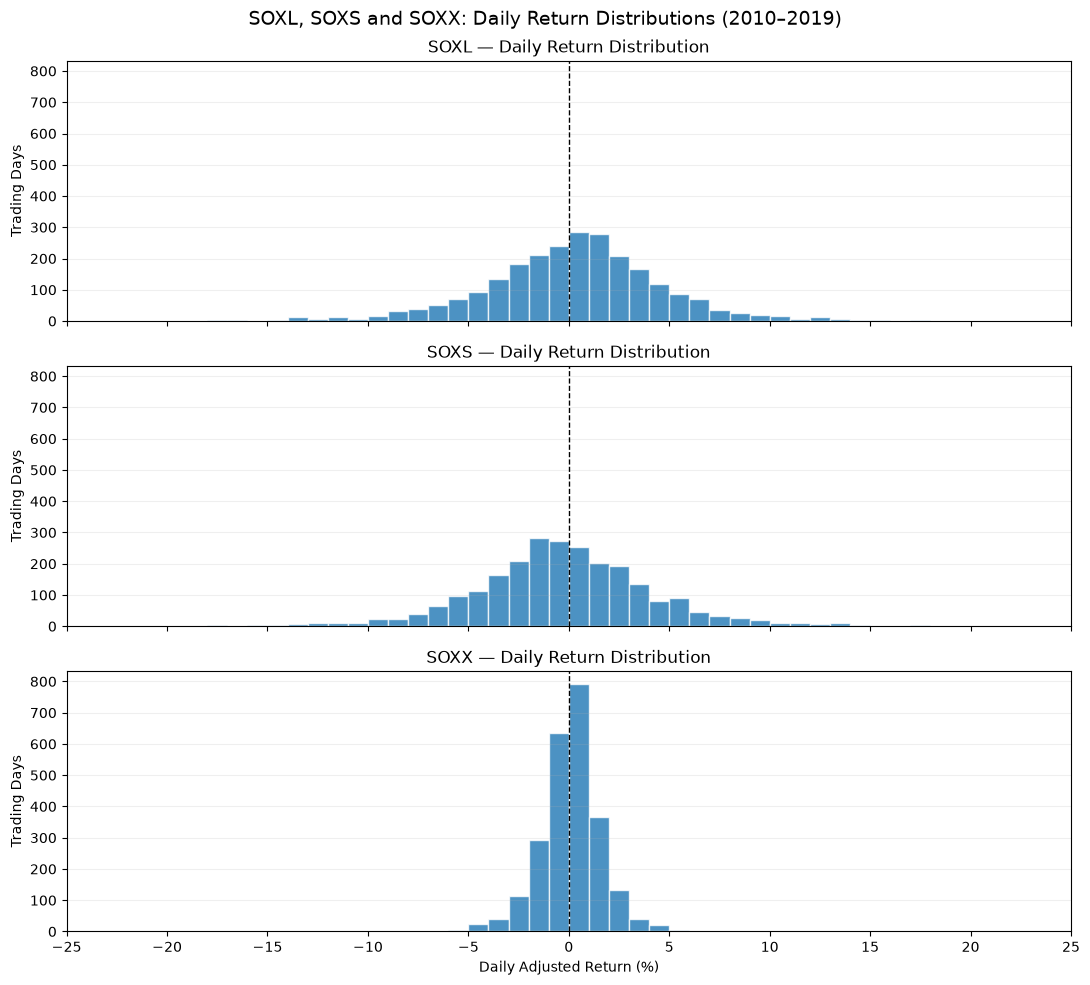

In [4]:

# ============================================================
# 2.2.3 — Daily Return Distribution Histograms
# Development period: 2010–2019
# ============================================================

# Create intervals of 1 percentage point.
bins = np.arange(-25, 26, 1)

# Create three charts stacked vertically.
fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(11, 10),
    sharex=True,
    sharey=True
)

# Generate one histogram for each ETF.
for ax, ticker in zip(axes, ["SOXL", "SOXS", "SOXX"]):

    returns = development_returns[f"{ticker} Return (%)"]

    ax.hist(
        returns,
        bins=bins,
        alpha=0.8,
        edgecolor="white"
    )

    # Dashed line marking zero return.
    ax.axvline(
        x=0,
        color="black",
        linestyle="--",
        linewidth=1
    )

    ax.set_title(f"{ticker} — Daily Return Distribution")
    ax.set_ylabel("Trading Days")
    ax.grid(axis="y", alpha=0.2)

# Keep the scales consistent across charts.
axes[-1].set_xlim(-25, 25)
axes[-1].set_xticks(np.arange(-25, 26, 5))
axes[-1].set_xlabel("Daily Adjusted Return (%)")

fig.suptitle(
    "SOXL, SOXS and SOXX: Daily Return Distributions (2010–2019)",
    fontsize=14
)

plt.tight_layout()
plt.show()



### 2.2.4 — Findings from Daily Return Distributions

#### 1. SOXL and SOXS Had Wider Return Distributions

The histograms show that SOXL and SOXS experienced a wider range of daily percentage returns than SOXX during 2010–2019.

Both leveraged ETFs recorded daily standard deviations of approximately **4.51%**, compared with **1.49%** for SOXX.

This difference is visible in the charts. SOXL and SOXS have more observations farther from 0%, while SOXX's distribution is concentrated closer to zero.

#### 2. Large Daily Gains and Losses Occurred in Both Leveraged ETFs

The historical extremes were:

| ETF | Worst Daily Return | Best Daily Return |
|---|---:|---:|
| SOXL | -20.72% | +17.48% |
| SOXS | -17.19% | +20.65% |
| SOXX | -6.89% | +6.00% |

These values show that the leveraged ETFs experienced substantially larger single-day movements in both directions.

The histograms also show relatively few observations far from zero. However, the extreme observations remain important because a small number of large losses can have a significant impact on investment performance.

#### 3. SOXX Returns Were More Concentrated Near Zero

SOXX's histogram has a noticeably taller central peak and a narrower spread.

This is consistent with its lower standard deviation.

The histogram suggests that large daily percentage movements were less common for SOXX than for the leveraged ETFs in the development period.

#### 4. Historical Distributions Are Not Forecasts

These charts describe observed daily returns from 2010–2019.

They do not tell us when a large loss will happen again or whether the same distribution will continue in the future.

A visual comparison also cannot establish whether returns follow a normal distribution or whether the ETFs have statistically heavier tails after accounting for their different volatility levels.

#### Research Implication

The results support investigating SOXL's historical downside risk more closely.

The next step is to examine how frequently large daily losses occurred, before moving into rolling volatility and volatility clustering.

All observations remain restricted to the development period.



### 2.2.5 — Frequency of Large Daily Losses

#### Objective

Measure how often SOXL, SOXS, and SOXX experienced large single-day losses during the 2010–2019 development period.

The histograms showed that leveraged ETFs had wider daily-return distributions. We now want to quantify how frequently substantial losses occurred.

#### What Is a Loss Threshold?

A loss threshold is a specified percentage decline.

We will examine three descriptive thresholds:

- **-3%:** A daily loss of at least 3%
- **-5%:** A daily loss of at least 5%
- **-10%:** A daily loss of at least 10%

For example, if SOXL recorded a return of -6%, that day would count toward the -3% and -5% thresholds, but not the -10% threshold.

These categories overlap. They should not be added together.

#### Calculating Historical Loss Frequency

$$
\text{Loss Frequency (\%)} =
\frac{\text{Number of days meeting the loss threshold}}
{\text{Total valid trading days}} \times 100
$$

For example, suppose an ETF experienced a loss of at least 5% on 50 out of 1,000 trading days.

$$
\frac{50}{1000} \times 100 = 5\%
$$

This means the specified loss occurred on 5% of the observed trading days.

#### Important Limitation

These thresholds compare absolute percentage losses, not losses relative to each ETF's typical volatility.

Because SOXL and SOXS are leveraged, larger daily changes are expected. A higher loss frequency at a fixed threshold does not automatically prove that their standardized return distributions have heavier tails.

These are historical frequencies, not forecasts of future loss probabilities.


In [5]:

# ============================================================
# 2.2.5 — Frequency of Large Daily Losses (2010–2019)
# ============================================================

# Loss magnitudes expressed in percentage points.
loss_thresholds = [3, 5, 10]

loss_rows = []

for ticker in ["SOXL", "SOXS", "SOXX"]:

    # Use only valid development-period daily returns.
    returns = development_returns[f"{ticker} Return (%)"]

    for threshold in loss_thresholds:

        # Count days with a return at or below the negative threshold.
        loss_count = (returns <= -threshold).sum()

        # Divide by the total number of valid observations.
        loss_percent = (loss_count / returns.count()) * 100

        loss_rows.append({
            "ETF": ticker,
            "Loss Threshold": f"≤ -{threshold}%",
            "Days": int(loss_count),
            "Total Days": int(returns.count()),
            "Frequency (%)": loss_percent
        })

# Build the comparison table.
loss_frequency = pd.DataFrame(loss_rows)

print("Historical Daily Loss Frequencies — 2010–2019")
print("Thresholds are cumulative, not mutually exclusive.\n")

display(loss_frequency.round(2))


Historical Daily Loss Frequencies — 2010–2019
Thresholds are cumulative, not mutually exclusive.



,ETF,Loss Threshold,Days,Total Days,Frequency (%)
0,SOXL,≤ -3%,486,2469,19.68
1,SOXL,≤ -5%,261,2469,10.57
2,SOXL,≤ -10%,51,2469,2.07
3,SOXS,≤ -3%,577,2469,23.37
4,SOXS,≤ -5%,298,2469,12.07
5,SOXS,≤ -10%,50,2469,2.03
6,SOXX,≤ -3%,69,2469,2.79
7,SOXX,≤ -5%,7,2469,0.28
8,SOXX,≤ -10%,0,2469,0.00



### 2.2.6 — Findings from Large Daily Loss Frequencies

#### 1. Large Daily Losses Were More Frequent for Leveraged ETFs

During the 2010–2019 development period, SOXL recorded a daily loss of at least 5% on **261 trading days (10.57%)**.

SOXS experienced losses of this magnitude on **298 trading days (12.07%)**, compared with only **7 days (0.28%)** for SOXX.

These results show that large absolute percentage declines occurred much more frequently in the leveraged ETFs.

#### 2. Losses of 10% or More Were Uncommon but Present

At the -10% threshold:

| ETF | Trading Days | Historical Frequency |
|---|---:|---:|
| SOXL | 51 | 2.07% |
| SOXS | 50 | 2.03% |
| SOXX | 0 | 0.00% |

SOXL and SOXS had nearly identical frequencies of daily losses of at least 10%.

SOXX recorded no such losses during this development period. Its worst observed daily return was -6.89%.

A zero historical count does not mean that such an event cannot happen in the future.

#### 3. Loss Frequency and Loss Severity Are Different

Loss frequency tells us how often a decline of a specified magnitude occurred.

Loss severity tells us how large the decline was.

For example, SOXS experienced more daily losses of at least 5% than SOXL, but SOXL had the larger single-day maximum loss magnitude:

- SOXL: -20.72%
- SOXS: -17.19%

Both measures are necessary for understanding downside risk.

#### 4. Important Methodological Limitations

The thresholds of -3%, -5%, and -10% are descriptive comparison points. They are not optimized forecasting thresholds or finalized model targets.

The threshold categories overlap. A loss of 12% is included in all three categories.

The comparison uses absolute percentage losses. It does not establish whether one ETF has more extreme returns after adjusting for its typical volatility.

Early SOXX data include predecessor IGW history, which requires caution when making exact-benchmark comparisons.

The calculations use only 2010–2019 data and do not estimate future probabilities.

### Section 2.2 — Overall Conclusion

The descriptive statistics, histograms, and loss-frequency analysis consistently show that SOXL and SOXS experienced substantially larger daily percentage movements than SOXX during the development period.

For SOXL, daily losses of at least 5% occurred on 10.57% of observed trading days, while losses of at least 10% occurred on 2.07% of days.

These findings establish the historical frequency and magnitude of large daily losses, but do not explain when market conditions become more volatile.

**Next research question:** Does SOXL's volatility remain relatively stable over time, or do periods of unusually large daily movements tend to occur together?

Section 2.3 will investigate historical rolling volatility and volatility clustering.



## 2.3 — Historical Volatility and Volatility Clustering

### 2.3.1 — Understanding Rolling Volatility

#### Objective

Investigate how the historical daily volatility of SOXL, SOXS, and SOXX changed over time during the 2010–2019 development period.

Section 2.2 calculated one standard deviation for the entire development period.

We now calculate volatility repeatedly using shorter, moving windows of historical daily returns.

#### What Is Historical Realized Volatility?

Historical realized volatility describes how much observed returns fluctuated over a past period.

We estimate it using the sample standard deviation of daily percentage returns.

A higher standard deviation indicates greater variability in returns.

Volatility measures the size of both positive and negative movements. It does not distinguish gains from losses, and it is not itself a measure of maximum downside risk.

#### What Is Rolling Volatility?

Rolling volatility calculates the standard deviation of returns over a moving window.

For example, a **10-day rolling volatility** calculation uses the 10 most recent trading-day returns.

When the next trading day arrives, the window moves forward by one observation:

- Day 10: Calculate volatility using Days 1–10.
- Day 11: Calculate volatility using Days 2–11.
- Day 12: Calculate volatility using Days 3–12.

This produces a time series showing how market volatility changed.

#### Comparing 10-Day and 20-Day Windows

| Window | Interpretation |
|---|---|
| 10 trading days | More responsive to recent market changes |
| 20 trading days | Smoother measure of volatility over a longer period |

A 10-day window reacts more quickly to large daily movements. A 20-day window usually changes more gradually.

Neither window automatically provides a better forecast.

These window lengths are used for descriptive exploration, not selected through predictive model testing.

#### Mathematical Formula

The sample standard deviation of returns is:

$$
s = \sqrt{\frac{\sum_{i=1}^{n}(R_i-\bar{R})^2}{n-1}}
$$

Where:

- $s$ = historical volatility, measured as sample standard deviation
- $R_i$ = daily percentage return
- $\bar{R}$ = average percentage return within the window
- $n$ = number of trading-day returns in the window

#### Simple Example

Suppose an investment recorded three daily returns:

| Day | Return |
|---|---:|
| 1 | -2% |
| 2 | +1% |
| 3 | +4% |

The mean return is +1%.

The sample standard deviation is:

$$
s = \sqrt{\frac{(-2-1)^2+(1-1)^2+(4-1)^2}{3-1}}
$$

$$
s = \sqrt{\frac{18}{2}} = 3\%
$$

This example uses a three-day window to demonstrate the calculation. Our actual analysis will use 10-day and 20-day windows.

#### How Python Calculates Rolling Volatility

We use:

`returns.rolling(window=10, min_periods=10).std(ddof=1)`

- `rolling(window=10)` selects a moving window of 10 observations.
- `min_periods=10` requires all 10 returns before producing a value.
- `std()` calculates the standard deviation.
- `ddof=1` specifies the sample standard deviation, dividing by $n-1$.

Because returns are already expressed as percentages, the resulting volatility values are also expressed in percentage points.

We will **not annualize** these values in this section.

#### Why Are the First Rolling Values Missing?

The first 10-day rolling volatility value needs 10 daily returns.

Therefore, the first 9 rows will have missing 10-day volatility values.

Similarly, the first 19 rows will have missing 20-day volatility values.

This is expected. We will not fill them with invented values.

#### Research Restrictions

All calculations use the 2010–2019 development dataset.

Each rolling value uses the current and preceding trading-day returns, never future observations.

The results describe historical volatility and do not establish forecasting ability.


In [6]:

# ============================================================
# 2.3.1 — Calculate Historical Rolling Volatility
# Development period: 2010–2019
# ============================================================

# Create a separate working table.
# This preserves the existing daily-return dataset.
development_volatility = development_returns[
    ["Date"] + return_columns
].copy()

# Calculate 10-day and 20-day rolling volatility for each ETF.
for ticker in ["SOXL", "SOXS", "SOXX"]:

    returns = development_volatility[f"{ticker} Return (%)"]

    development_volatility[f"{ticker} Volatility 10d (%)"] = (
        returns.rolling(window=10, min_periods=10).std(ddof=1)
    )

    development_volatility[f"{ticker} Volatility 20d (%)"] = (
        returns.rolling(window=20, min_periods=20).std(ddof=1)
    )

# Check how many valid rolling values were calculated.
validation_rows = []

for ticker in ["SOXL", "SOXS", "SOXX"]:
    for window in [10, 20]:

        column = f"{ticker} Volatility {window}d (%)"

        validation_rows.append({
            "ETF": ticker,
            "Window (Days)": window,
            "Valid Values": development_volatility[column].count(),
            "Expected Values": len(development_volatility) - window + 1,
            "First Valid Date": development_volatility.loc[
                development_volatility[column].notna(), "Date"
            ].min()
        })

rolling_validation = pd.DataFrame(validation_rows)

# Verify that the calculation produced the expected counts.
assert (
    rolling_validation["Valid Values"]
    == rolling_validation["Expected Values"]
).all()

# Verify that the analysis remains inside the development period.
assert development_volatility["Date"].max() <= pd.Timestamp("2019-12-31")

print("Rolling Volatility Validation — 2010–2019")
display(rolling_validation)

# Display the last five observations for SOXL.
print("\nSOXL — Last Five Rolling Volatility Observations")

display(
    development_volatility[
        [
            "Date",
            "SOXL Return (%)",
            "SOXL Volatility 10d (%)",
            "SOXL Volatility 20d (%)"
        ]
    ].tail(5).round(2)
)


Rolling Volatility Validation — 2010–2019


,ETF,Window (Days),Valid Values,Expected Values,First Valid Date
0,SOXL,10,2460,2460,2010-03-25
1,SOXL,20,2450,2450,2010-04-09
2,SOXS,10,2460,2460,2010-03-25
3,SOXS,20,2450,2450,2010-04-09
4,SOXX,10,2460,2460,2010-03-25
5,SOXX,20,2450,2450,2010-04-09



SOXL — Last Five Rolling Volatility Observations


,Date,SOXL Return (%),SOXL Volatility 10d (%),SOXL Volatility 20d (%)
2465,2019-12-24,0.74,2.99,3.40
2466,2019-12-26,0.38,2.66,3.35
2467,2019-12-27,-1.11,1.61,3.38
2468,2019-12-30,-2.10,1.69,3.32
2469,2019-12-31,0.67,1.54,3.06



### 2.3.2 — Visualizing SOXL Rolling Volatility

#### Objective

Visualize changes in SOXL's historical daily-return volatility throughout the 2010–2019 development period.

We will compare 10-day and 20-day rolling standard deviations to investigate whether volatility remained stable or changed over time.

#### How to Read the Chart

- **X-axis:** Trading date
- **Y-axis:** Rolling standard deviation of daily returns (%)
- **10-day line:** Volatility calculated from the most recent 10 trading-day returns
- **20-day line:** Volatility calculated from the most recent 20 trading-day returns

A high point indicates that daily returns varied substantially within the corresponding historical window.

A low point indicates that returns were relatively stable during that window.

Because the 10-day calculation uses fewer observations, it is generally more responsive to recent changes.

#### What Is Volatility Clustering?

Volatility clustering describes the tendency for periods of large return movements to occur near other periods of large movements.

In financial markets, periods of high volatility may persist for some time rather than appearing as isolated events.

We will first look for these patterns visually. Later in Section 2.3, we will examine return magnitudes more directly.

Rolling-volatility charts are descriptive. Overlapping windows can create smooth, persistent-looking patterns by construction, so the chart alone cannot prove volatility clustering or predictive ability.

#### Research Restrictions

This visualization uses only 2010–2019 development observations.

The lines represent historical daily-return standard deviations, not annualized volatility.

No future returns are used in the rolling calculations.


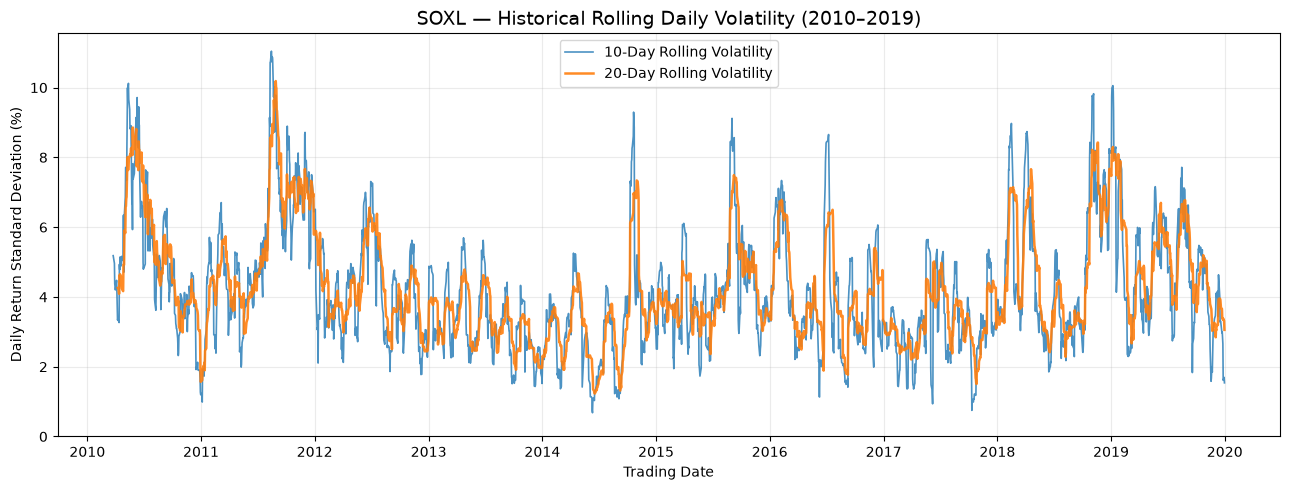

In [7]:

# ============================================================
# 2.3.2 — SOXL Historical Rolling Volatility Chart
# Development period: 2010–2019
# ============================================================

# Create a single figure for comparing the two windows.
fig, ax = plt.subplots(figsize=(13, 5))

# Plot the 10-day rolling volatility.
ax.plot(
    development_volatility["Date"],
    development_volatility["SOXL Volatility 10d (%)"],
    label="10-Day Rolling Volatility",
    linewidth=1.2,
    alpha=0.8
)

# Plot the 20-day rolling volatility.
ax.plot(
    development_volatility["Date"],
    development_volatility["SOXL Volatility 20d (%)"],
    label="20-Day Rolling Volatility",
    linewidth=1.8,
    alpha=0.9
)

# Chart title and axis labels.
ax.set_title(
    "SOXL — Historical Rolling Daily Volatility (2010–2019)",
    fontsize=14
)

ax.set_xlabel("Trading Date")
ax.set_ylabel("Daily Return Standard Deviation (%)")

# Volatility cannot be negative.
ax.set_ylim(bottom=0)

# Add legend and grid.
ax.legend()
ax.grid(alpha=0.25)

# Improve layout and display.
plt.tight_layout()
plt.show()



#### Findings from SOXL Rolling Volatility

**1. SOXL's Historical Volatility Was Not Constant**

SOXL's rolling daily-return standard deviation changed substantially throughout 2010–2019.

The chart shows periods of elevated volatility around 2010–2011, parts of 2015, and 2018–2019. Other periods experienced considerably smaller daily fluctuations.

The overall development-period standard deviation of 4.51% therefore hides substantial variation over time.

**2. The 10-Day Window Responded More Quickly**

The 10-day volatility line has sharper peaks and declines than the 20-day line.

This occurs because the shorter calculation responds more strongly when a large daily return enters or leaves its rolling window.

The 20-day measure is generally smoother because it incorporates more observations.

**3. Elevated Volatility Sometimes Persisted**

Some periods show high volatility remaining elevated across multiple trading days rather than disappearing immediately.

This pattern is consistent with the possibility of volatility clustering.

However, consecutive rolling windows share most of their observations. Their overlapping structure can produce persistent-looking movements even without an independently established clustering relationship.

We therefore cannot use this chart alone as proof of volatility clustering.

**4. Implications for Downside Risk Research**

A single long-term standard deviation does not adequately describe how SOXL's historical risk conditions varied.

Periods with higher realized volatility may contain larger daily gains and losses, but volatility itself does not identify the direction of the next return.

Later analyses will examine whether historical volatility conditions contain useful information about subsequent downside risk.

No predictive conclusion is made at this stage.

#### Next Investigation

Compare rolling volatility across SOXL, SOXS, and SOXX, then examine whether large absolute returns tend to occur close together.



### 2.3.3 — Comparing Historical Volatility Across ETFs

#### Objective

Compare the 20-day rolling volatility of SOXL, SOXS, and SOXX during the 2010–2019 development period.

Section 2.3.2 showed that SOXL's volatility changed substantially over time.

We now want to investigate whether similar periods of elevated volatility appeared in the inverse leveraged ETF (SOXS) and the unleveraged semiconductor ETF (SOXX).

#### Why Compare the Three ETFs?

The three ETFs provide different types of semiconductor-sector exposure:

| ETF | Exposure |
|---|---|
| SOXL | Daily leveraged long semiconductor exposure |
| SOXS | Daily leveraged inverse semiconductor exposure |
| SOXX | Unleveraged semiconductor-sector ETF |

SOXL and SOXS historically targeted approximately +3× and -3× daily exposure to their respective underlying benchmarks.

However, historical benchmark definitions and tracking differences must be considered. SOXX is a useful comparison ETF, not necessarily the exact benchmark underlying SOXL and SOXS throughout the period.

#### Why Use 20-Day Volatility?

We have already calculated both 10-day and 20-day rolling volatility.

For this comparison, we will focus on the 20-day measure because it produces a somewhat smoother view of historical volatility conditions.

Each value uses the current and preceding 19 trading-day returns.

The calculation remains:

`returns.rolling(window=20, min_periods=20).std(ddof=1)`

All values represent the standard deviation of daily percentage returns. They are **not annualized**.

#### Why Use the Same Vertical Scale?

All three charts will share the same y-axis.

If one chart uses a scale of 0–5% and another uses 0–15%, their movements may appear equally large even when their actual volatility levels differ substantially.

Using matching scales makes the comparison more meaningful.

#### Questions to Investigate

1. Did SOXL and SOXS experience elevated volatility at similar times?
2. Did SOXX show increases in volatility during those same periods?
3. Were the leveraged ETFs consistently more volatile than SOXX?
4. Did periods of elevated volatility affect all three ETFs equally?

#### Interpretation Limitations

Similar volatility patterns do not prove that the ETFs tracked the same benchmark or had identical risks.

The charts also cannot establish whether volatility is useful for forecasting future losses.

All calculations remain restricted to the 2010–2019 development period.


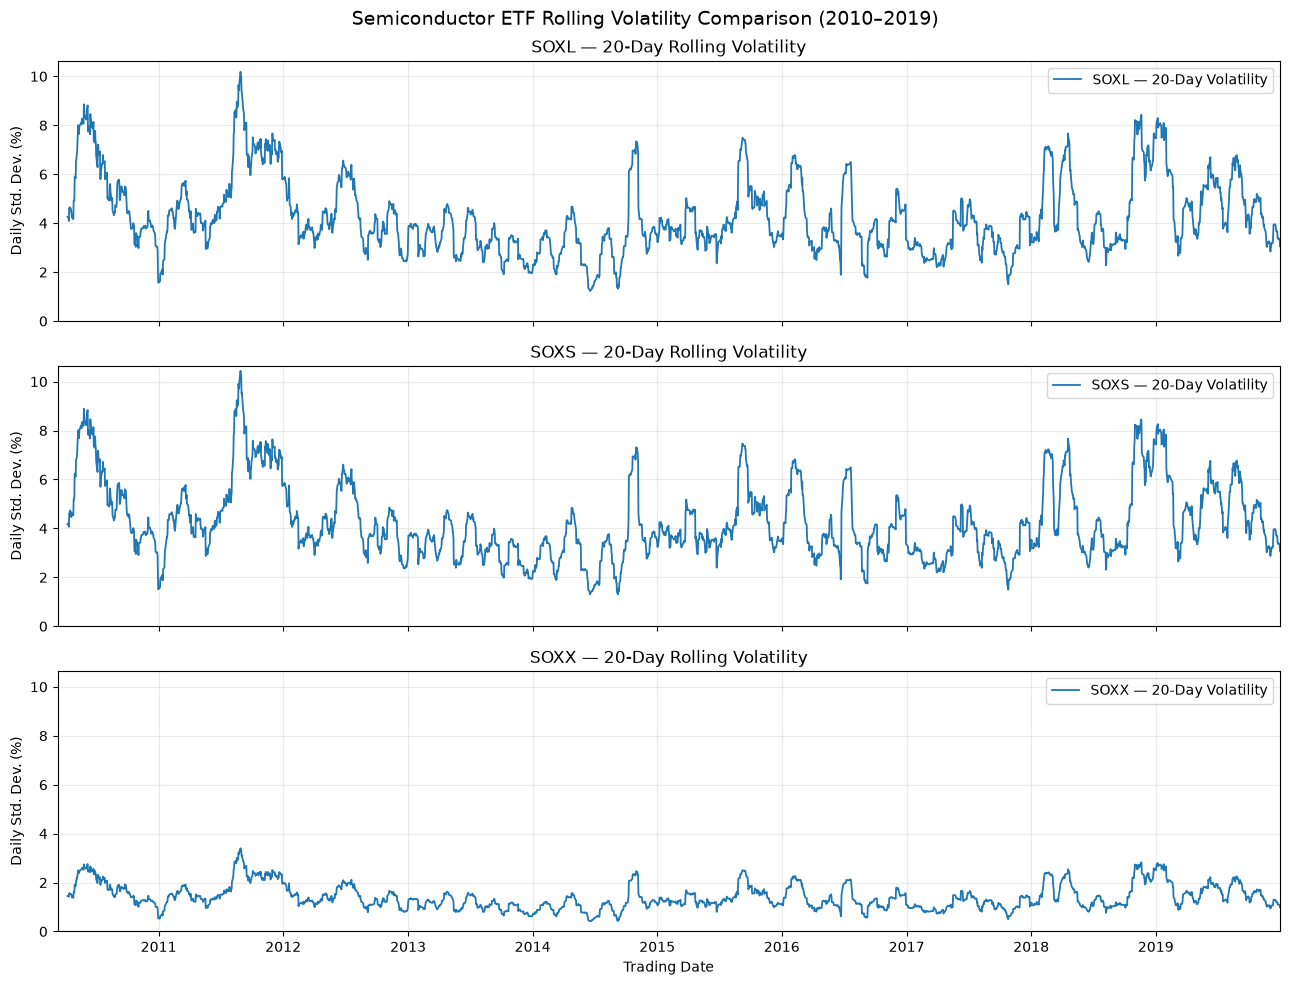

In [8]:

# ============================================================
# 2.3.3 — Compare 20-Day Rolling Volatility Across ETFs
# Development period: 2010–2019
# ============================================================

# Create three vertically stacked charts.
# sharex=True and sharey=True keep the axes consistent.
fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(13, 10),
    sharex=True,
    sharey=True
)

# Generate one chart for each ETF.
for ax, ticker in zip(axes, ["SOXL", "SOXS", "SOXX"]):

    volatility_column = f"{ticker} Volatility 20d (%)"

    ax.plot(
        development_volatility["Date"],
        development_volatility[volatility_column],
        linewidth=1.3,
        label=f"{ticker} — 20-Day Volatility"
    )

    ax.set_title(f"{ticker} — 20-Day Rolling Volatility")
    ax.set_ylabel("Daily Std. Dev. (%)")
    ax.set_ylim(bottom=0)
    ax.legend(loc="upper right")
    ax.grid(alpha=0.25)

# Restrict the horizontal axis to our development period.
axes[-1].set_xlim(
    pd.Timestamp("2010-03-11"),
    pd.Timestamp("2019-12-31")
)

axes[-1].set_xlabel("Trading Date")

fig.suptitle(
    "Semiconductor ETF Rolling Volatility Comparison (2010–2019)",
    fontsize=14
)

plt.tight_layout()
plt.show()



#### Findings from the ETF Rolling Volatility Comparison

**1. SOXL and SOXS Had Similar Volatility Patterns**

The 20-day rolling volatility charts for SOXL and SOXS follow very similar paths throughout the 2010–2019 development period.

Their major volatility increases and decreases occurred at approximately the same times.

Although SOXL and SOXS provide opposite daily market exposure, standard deviation measures the magnitude of return fluctuations rather than their direction.

This helps explain why their historical volatility patterns were similar.

Their volatility is not necessarily identical because of tracking differences, fees, and other fund-specific effects.

**2. SOXX Had Substantially Lower Volatility**

SOXX's 20-day rolling volatility remained considerably lower than the leveraged ETFs' volatility across most of the development period.

During a prominent period of elevated volatility in 2011, SOXL and SOXS reached approximately 10% daily rolling standard deviation, compared with roughly 3–3.5% for SOXX.

These values are approximate readings from the charts.

The shared vertical scale makes the difference in volatility magnitude visible.

**3. Elevated Volatility Occurred at Similar Times**

All three ETFs showed notable volatility increases during parts of 2010–2011, 2015, and 2018–2019.

The timing suggests that semiconductor-sector market conditions may contribute to periods of elevated volatility across these ETFs.

However, similar timing does not establish a causal relationship or prove that one ETF's volatility can forecast another ETF's future returns.

**4. Leverage Amplified the Magnitude of Daily Fluctuations**

The leveraged ETFs generally experienced much larger rolling standard deviations than SOXX.

This is consistent with their daily leveraged exposure and the earlier full-period standard deviation comparison:

- SOXL: 4.51%
- SOXS: 4.51%
- SOXX: 1.49%

These are full-period daily standard deviations, not averages of the 20-day rolling estimates.

**5. Limitations**

Rolling windows overlap, so persistent-looking movements in the charts cannot independently establish volatility clustering.

SOXX is a sector comparison ETF and was not necessarily the exact underlying benchmark for SOXL or SOXS.

Early SOXX observations also include predecessor IGW history.

The charts describe historical relationships using only 2010–2019 observations. They do not establish predictive accuracy.

#### Next Investigation

Examine volatility clustering more directly by studying whether large absolute daily returns tend to occur near other large absolute returns.



### 2.3.4 — Investigating Volatility Clustering

#### Objective

Investigate whether large daily return movements tend to occur near other large movements during the 2010–2019 development period.

Our rolling-volatility charts showed periods of elevated volatility, but overlapping rolling windows can make volatility appear persistent.

We will now examine the daily returns directly.

#### What Is Volatility Clustering?

Volatility clustering describes a tendency for large return movements to occur near other large movements, and small movements to occur near other small movements.

For example, after an unusually large daily price movement, the market may continue experiencing substantial fluctuations over subsequent days.

Importantly, volatility clustering concerns the **magnitude of returns**, not necessarily their direction.

A large loss followed by a large gain can still represent a period of elevated volatility.

#### What Are Absolute Returns?

The absolute value removes the positive or negative sign from a number.

For example:

| Daily Return | Absolute Return |
|---|---:|
| +5% | 5% |
| -5% | 5% |
| +1% | 1% |
| -8% | 8% |

Mathematically:

$$
A_t = |R_t|
$$

Where:

- $R_t$ = daily percentage return
- $A_t$ = absolute daily percentage return

Absolute returns provide a simple way to measure the size of daily movements without distinguishing gains from losses.

They are not the same as rolling standard deviation, but both can provide information about historical volatility.

#### What Is Autocorrelation?

Autocorrelation measures the statistical relationship between a time series and an earlier version of itself.

For this investigation, we compare today's absolute return with the absolute return from previous trading days.

For example:

- **Lag 1:** Today's absolute return versus the previous trading day's absolute return.
- **Lag 5:** Today's absolute return versus the absolute return five trading days earlier.
- **Lag 10:** Today's absolute return versus ten trading days earlier.
- **Lag 20:** Today's absolute return versus twenty trading days earlier.

The autocorrelation coefficient ranges from -1 to +1.

| Value | Interpretation |
|---|---|
| Positive | Larger movements tend to be associated with larger earlier movements |
| Near zero | Little linear relationship at that lag |
| Negative | Larger movements tend to be associated with smaller earlier movements |

#### Simple Example

Suppose an ETF experiences the following daily returns:

| Day | Daily Return | Absolute Return |
|---|---:|---:|
| Monday | -6% | 6% |
| Tuesday | +5% | 5% |
| Wednesday | -7% | 7% |
| Thursday | +1% | 1% |
| Friday | -0.5% | 0.5% |

The first three days have large absolute movements, despite having different return directions.

This illustrates the type of pattern we want to investigate.

Five observations are not enough to establish a reliable statistical relationship. Our actual analysis uses the development-period return series.

#### How Python Calculates Autocorrelation

We will use:

`returns.abs().autocorr(lag=1)`

- `.abs()` converts each daily return into its absolute magnitude.
- `.autocorr()` calculates the correlation between the series and a shifted copy.
- `lag=1` compares observations separated by one trading day.

We will repeat this calculation for lags 1, 5, 10, and 20.

We will also calculate lag-1 autocorrelation of the original signed returns for comparison.

#### Interpretation Limitations

Positive autocorrelation in absolute returns is consistent with volatility clustering, but it does not establish causation or guarantee future predictability.

A correlation coefficient is a descriptive statistical measure. We are not conducting a formal significance test or estimating a forecasting model in this section.

All calculations use only the 2010–2019 development period.


In [9]:

# ============================================================
# 2.3.4 — Absolute Return Autocorrelation
# Development period: 2010–2019
# ============================================================

# Lags represent the number of trading days between returns.
lags = [1, 5, 10, 20]

autocorrelation_rows = []

for ticker in ["SOXL", "SOXS", "SOXX"]:

    # Retrieve daily percentage returns.
    returns = development_returns[f"{ticker} Return (%)"]

    # Convert returns to absolute magnitudes.
    absolute_returns = returns.abs()

    for lag in lags:

        # Compare absolute returns separated by this many days.
        correlation = absolute_returns.autocorr(lag=lag)

        autocorrelation_rows.append({
            "ETF": ticker,
            "Lag (Trading Days)": lag,
            "Observations Paired": len(returns) - lag,
            "Absolute Return Autocorrelation": correlation
        })

# Combine the results into one table.
autocorrelation_results = pd.DataFrame(
    autocorrelation_rows
)

print("Absolute Return Autocorrelation — 2010–2019")
display(autocorrelation_results.round(4))

# Compare signed-return and absolute-return autocorrelation.
comparison_rows = []

for ticker in ["SOXL", "SOXS", "SOXX"]:

    returns = development_returns[f"{ticker} Return (%)"]

    comparison_rows.append({
        "ETF": ticker,
        "Signed Return Lag-1": returns.autocorr(lag=1),
        "Absolute Return Lag-1": returns.abs().autocorr(lag=1)
    })

autocorrelation_comparison = pd.DataFrame(
    comparison_rows
).set_index("ETF")

print("\nSigned vs. Absolute Return Autocorrelation — Lag 1")
display(autocorrelation_comparison.round(4))


Absolute Return Autocorrelation — 2010–2019


,ETF,Lag (Trading Days),Observations Paired,Absolute Return Autocorrelation
0,SOXL,1,2468,0.1164
1,SOXL,5,2464,0.1082
2,SOXL,10,2459,0.1413
3,SOXL,20,2449,0.0511
4,SOXS,1,2468,0.1148
5,SOXS,5,2464,0.1113
6,SOXS,10,2459,0.1415
7,SOXS,20,2449,0.0541
8,SOXX,1,2468,0.1068
9,SOXX,5,2464,0.0982



Signed vs. Absolute Return Autocorrelation — Lag 1


,Signed Return Lag-1,Absolute Return Lag-1
ETF,,
SOXL,-0.0123,0.1164
SOXS,-0.0180,0.1148
SOXX,-0.0091,0.1068



#### Findings from Absolute-Return Autocorrelation

**1. Positive Autocorrelation Was Observed Across All Three ETFs**

All three ETFs had positive absolute-return autocorrelation at lags 1, 5, 10, and 20 trading days.

For SOXL, the observed coefficients were:

| Lag (Trading Days) | Absolute-Return Autocorrelation |
|---|---:|
| 1 | 0.1164 |
| 5 | 0.1082 |
| 10 | 0.1413 |
| 20 | 0.0511 |

These positive correlations are consistent with the tendency for larger daily movements to occur near other larger movements.

However, the coefficients are relatively small. We should not interpret them as evidence of a strong or guaranteed relationship.

**2. Return Magnitude Showed More Persistence Than Return Direction**

SOXL's lag-1 signed-return autocorrelation was **-0.0123**, compared with **+0.1164** for absolute returns.

SOXS and SOXX showed a similar difference.

This distinction suggests that the magnitude of daily movements had a stronger historical linear association with earlier magnitudes than signed returns had with earlier signed returns.

In other words, large market movements may occur near one another even when their direction is difficult to anticipate.

**3. Similar Patterns Appeared Across All Three ETFs**

The lag-1 absolute-return autocorrelations were:

- SOXL: 0.1164
- SOXS: 0.1148
- SOXX: 0.1068

All three ETFs had positive coefficients of similar magnitude.

This suggests that the observed persistence in return magnitudes was not unique to SOXL or SOXS.

The similarities are consistent with their shared exposure to semiconductor-sector market conditions, but do not establish a causal relationship.

**4. Autocorrelation Varied Across Lags**

SOXL's absolute-return autocorrelation was highest among the selected lags at 10 trading days (0.1413).

It was lower at 20 trading days (0.0511).

The pattern did not decline consistently across every lag, so we cannot describe it as a smooth decay.

These results describe associations at four selected lags, not the complete autocorrelation structure.

**5. Limitations and Research Implications**

Positive autocorrelation in absolute returns provides descriptive evidence consistent with volatility clustering.

However:

- Correlation does not establish causation.
- The coefficients do not represent probabilities of future losses.
- No formal statistical significance test has been conducted.
- The analysis does not establish that these relationships remain stable outside 2010–2019.
- No forecasting model has been trained or evaluated.

The findings support further investigation of historical volatility conditions as potential inputs to later downside-risk models.

Predictive usefulness must be assessed separately using properly lagged features and out-of-sample evaluation.

#### Next Step

Visualize the absolute-return autocorrelation coefficients to compare their magnitudes across the three ETFs and four trading-day lags.



### 2.3.5 — Visualizing Absolute-Return Autocorrelation

#### Objective

Compare the absolute-return autocorrelation coefficients of SOXL, SOXS, and SOXX at lags of 1, 5, 10, and 20 trading days.

The previous calculations showed positive autocorrelation across all three ETFs.

We will use a grouped bar chart to visualize these relationships.

#### How to Read the Chart

- **X-axis:** Number of trading days separating the observations.
- **Y-axis:** Absolute-return autocorrelation coefficient.
- **Grouped bars:** Compare SOXL, SOXS, and SOXX at each lag.
- **Higher positive values:** Stronger positive linear association between absolute returns at that lag.
- **Values near zero:** Weaker linear association.

For example, SOXL's lag-1 coefficient was 0.1164.

This describes a weak positive historical correlation between today's absolute return and the previous trading day's absolute return.

It does **not** mean there is an 11.64% probability of a large movement tomorrow.

#### What We Want to Investigate

1. How similar are the autocorrelation coefficients across the three ETFs?
2. Which of the selected lags has the highest observed coefficient?
3. Do the coefficients consistently decrease as the lag increases?
4. What does this tell us about historical volatility clustering?

#### Important Limitation

The chart compares descriptive correlation coefficients.

It does not test statistical significance, demonstrate causation, or establish forecasting accuracy.

Only 2010–2019 development data are used.


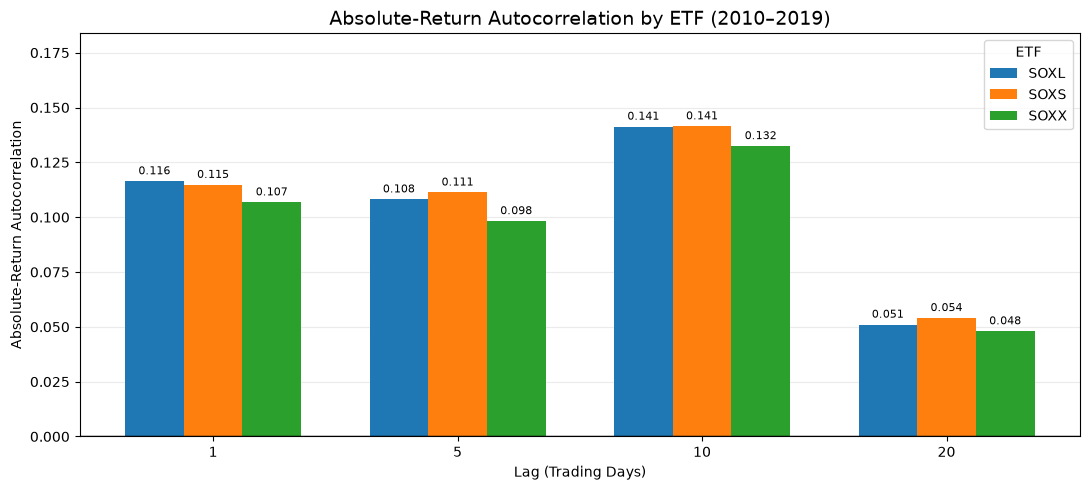

In [10]:

# ============================================================
# 2.3.5 — Visualize Absolute-Return Autocorrelation
# Development period: 2010–2019
# ============================================================

# Trading-day lags already examined.
lags = [1, 5, 10, 20]

# Positions of the four groups on the horizontal axis.
x = np.arange(len(lags))

# Width of each ETF's bar.
bar_width = 0.24

fig, ax = plt.subplots(figsize=(11, 5))

# Plot the three ETFs side by side at each lag.
for i, ticker in enumerate(["SOXL", "SOXS", "SOXX"]):

    # Retrieve the four coefficients in the correct lag order.
    values = (
        autocorrelation_results.loc[
            autocorrelation_results["ETF"] == ticker
        ]
        .set_index("Lag (Trading Days)")
        .loc[lags, "Absolute Return Autocorrelation"]
        .to_numpy()
    )

    # Offset the bars so they appear next to one another.
    positions = x + (i - 1) * bar_width

    bars = ax.bar(
        positions,
        values,
        width=bar_width,
        label=ticker
    )

    # Display the coefficient above each bar.
    ax.bar_label(
        bars,
        fmt="%.3f",
        padding=3,
        fontsize=8
    )

# Reference line representing zero correlation.
ax.axhline(0, color="black", linewidth=1)

# Axis labels and title.
ax.set_xticks(x)
ax.set_xticklabels(lags)

ax.set_xlabel("Lag (Trading Days)")
ax.set_ylabel("Absolute-Return Autocorrelation")

ax.set_title(
    "Absolute-Return Autocorrelation by ETF (2010–2019)",
    fontsize=14
)

# Give labels some room above the tallest bar.
ax.set_ylim(
    bottom=0,
    top=autocorrelation_results[
        "Absolute Return Autocorrelation"
    ].max() * 1.3
)

ax.legend(title="ETF")
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()



### 2.3.6 — Historical Volatility: Overall Findings

#### Summary of Results

The 2010–2019 development-period analysis provides three main findings.

**1. Historical volatility changed considerably over time.**

SOXL's 10-day and 20-day rolling standard deviations showed repeated periods of elevated and reduced volatility.

A single standard deviation calculated over the entire development period does not capture these changes in market conditions.

**2. Leveraged ETFs experienced substantially greater volatility.**

SOXL and SOXS had similar 20-day rolling volatility patterns, with much larger fluctuations than SOXX.

All three ETFs experienced elevated volatility at approximately the same times, suggesting shared exposure to changing semiconductor-sector conditions.

This comparison is descriptive. SOXX was not necessarily the exact underlying benchmark for the leveraged ETFs throughout the period.

**3. Absolute returns showed positive autocorrelation.**

SOXL's absolute-return autocorrelation was:

- Lag 1: 0.1164
- Lag 5: 0.1082
- Lag 10: 0.1413
- Lag 20: 0.0511

SOXS and SOXX showed similar patterns.

The grouped bar chart confirms that all three ETFs had positive autocorrelation at the selected lags, with the strongest observed association at lag 10.

These correlations are relatively weak but consistent with historical volatility clustering.

#### Why This Matters for Our Research

Our project investigates whether semiconductor market conditions and historical volatility can help estimate near-term SOXL downside risk.

The analysis establishes that SOXL's historical volatility was not constant and that daily return magnitudes showed some persistence.

This gives us a reason to investigate historical volatility as a possible risk-related variable in later stages.

However, we have **not established that volatility predicts future SOXL losses**.

That question requires properly lagged information, defined downside outcomes, and out-of-sample evaluation.

#### Limitations

- Rolling volatility describes past returns and cannot directly identify the direction of future price movements.
- Overlapping rolling windows can produce apparent persistence.
- Absolute-return autocorrelation does not establish causation or predictive accuracy.
- No formal autocorrelation significance tests have been conducted.
- The analysis uses only 2010–2019 development observations.
- Findings may not remain stable during later market periods.

#### Section 2.3 Conclusion

The historical evidence shows that SOXL experienced changing volatility conditions and positive autocorrelation in absolute daily returns.

These results support further research into downside-risk estimation without demonstrating forecasting ability.

**Next: Section 2.4 — Daily Leverage Relationships**

We will investigate how SOXL's and SOXS's daily returns relate to semiconductor-sector movements, including differences from their approximate +3x and -3x daily leverage objectives.



## 2.4 — Daily Leverage Relationships

### 2.4.1 — Understanding Daily Leveraged Exposure

#### Objective

Investigate the contemporaneous relationships between the daily adjusted returns of SOXL, SOXS, and SOXX during the development period.

We want to understand how leveraged and inverse semiconductor ETFs move relative to an unleveraged semiconductor-sector comparison.

#### What Is a Leveraged ETF?

A leveraged exchange-traded fund aims to produce a specified multiple of its underlying benchmark's **daily return**.

SOXL and SOXS are designed around opposite daily leveraged exposures:

| ETF | Daily Exposure Objective |
|---|---|
| SOXL | Approximately +3× its underlying benchmark's daily return |
| SOXS | Approximately -3× its underlying benchmark's daily return |
| SOXX | Unleveraged semiconductor-sector exposure |

The +3× and -3× objectives apply to daily benchmark performance, not necessarily returns over several days, months, or years.

#### Worked Example

Suppose an underlying semiconductor benchmark rises by 2% in one trading day.

Ignoring fees and tracking differences:

$$
R_{\text{SOXL}} \approx 3 \times 2\% = +6\%
$$

$$
R_{\text{SOXS}} \approx -3 \times 2\% = -6\%
$$

If the benchmark instead falls by 2%, the illustrative daily returns reverse:

- SOXL: approximately -6%
- SOXS: approximately +6%

These examples describe intended daily leverage, not guaranteed realized ETF returns.

#### Why Isn't Daily Leverage Always Exactly 3×?

Actual ETF returns can differ from a simple leverage calculation because of:

- Fund expenses and financing costs
- Derivative pricing and portfolio management
- Benchmark tracking differences
- Differences in market closing prices and adjusted-price methodology
- Historical changes in the benchmark or fund structure

Daily leverage also does not imply that multi-day returns are exactly three times the benchmark's cumulative return.

We will investigate compounding separately in Section 2.5.

#### Important Benchmark Limitation

SOXX is useful as an unleveraged semiconductor-sector comparison, but it is not necessarily the exact benchmark underlying SOXL or SOXS.

Additionally, the historical SOXX dataset includes predecessor IGW history before October 15, 2010.

For the initial cross-ETF comparison, we will begin on **October 18, 2010**, the next trading day after that transition, so each compared return uses dates after the predecessor period.

This restriction does not make SOXX an exact leveraged-fund benchmark. It only avoids mixing the predecessor period into this particular comparison.

#### What Is Correlation?

Correlation measures how strongly two variables move together in a linear relationship.

The Pearson correlation coefficient ranges from -1 to +1.

| Correlation | Interpretation |
|---|---|
| Near +1 | Strong positive relationship |
| Near 0 | Weak linear relationship |
| Near -1 | Strong negative relationship |

For example, a strong positive correlation between SOXL and SOXX would mean their daily returns generally moved together.

A strong negative correlation between SOXS and SOXX would mean their daily returns generally moved in opposite directions.

**Correlation does not measure the leverage multiple.**

Two return series can have a correlation near +1 even if one moves approximately three times as much as the other.

#### Research Restrictions

This analysis:

- Uses adjusted daily percentage returns.
- Includes only development-period observations through December 31, 2019.
- Compares returns from matching trading dates.
- Treats SOXX as a sector comparison, not an exact benchmark.
- Does not estimate forecasting models or evaluate future returns.


In [11]:

# ============================================================
# 2.4.1 — Same-Day ETF Return Relationships
# Development period: October 18, 2010 – December 31, 2019
# ============================================================

# Use dates after the SOXX predecessor-history transition.
leverage_comparison = development_returns.loc[
    development_returns["Date"] >= pd.Timestamp("2010-10-18"),
    ["Date"] + return_columns
].copy()

# Confirm that we have a clean, aligned comparison dataset.
assert not leverage_comparison.empty
assert leverage_comparison["Date"].is_unique
assert leverage_comparison[return_columns].notna().all().all()

assert leverage_comparison["Date"].min() >= pd.Timestamp("2010-10-18")
assert leverage_comparison["Date"].max() <= pd.Timestamp("2019-12-31")

print("Daily Leverage Comparison — Data Validation")
print("First date:", leverage_comparison["Date"].min().date())
print("Last date:", leverage_comparison["Date"].max().date())
print("Matched trading days:", len(leverage_comparison))

# Calculate same-day Pearson return correlations.
correlation_matrix = leverage_comparison[
    return_columns
].corr(method="pearson")

# Make labels easier to read.
correlation_matrix.index = ["SOXL", "SOXS", "SOXX"]
correlation_matrix.columns = ["SOXL", "SOXS", "SOXX"]

print("\nSame-Day Daily Return Correlations")
display(correlation_matrix.round(4))


Daily Leverage Comparison — Data Validation
First date: 2010-10-18
Last date: 2019-12-31
Matched trading days: 2317

Same-Day Daily Return Correlations


,SOXL,SOXS,SOXX
SOXL,1.0000,-0.9987,0.9980
SOXS,-0.9987,1.0000,-0.9979
SOXX,0.9980,-0.9979,1.0000



### 2.4.2 — Findings from Daily Return Correlations

#### 1. SOXL and SOXX Had a Strong Positive Relationship

The Pearson correlation between SOXL and SOXX daily adjusted returns was **+0.9980** across 2,317 matched trading days.

This indicates an extremely strong positive linear relationship during the October 18, 2010–December 31, 2019 comparison period.

Their returns generally moved in the same direction, consistent with their shared exposure to semiconductor-sector movements.

#### 2. SOXS Moved in the Opposite Direction

SOXS had a daily-return correlation of **-0.9979** with SOXX.

Its correlation with SOXL was **-0.9987**.

These strong negative relationships are consistent with SOXS providing inverse daily semiconductor exposure.

The relationships are not perfectly negative, meaning the daily returns were not exact mirror images.

#### 3. Correlation Does Not Measure the Leverage Multiple

A correlation close to +1 or -1 does not tell us whether an ETF moves by 1×, 2×, or 3× another investment's daily return.

For example, the following returns have a perfect positive correlation:

| Trading Day | ETF A | ETF B |
|---|---:|---:|
| Day 1 | +1% | +3% |
| Day 2 | -2% | -6% |
| Day 3 | +2% | +6% |

ETF B moves by three times ETF A's return, but their correlation is still +1.

To investigate leverage magnitude, we need to examine how much SOXL and SOXS move for each percentage-point change in SOXX.

We will use daily-return scatterplots and fitted descriptive relationships in the next investigation.

#### 4. Benchmark and Methodological Limitations

The comparison includes **2,317 matched trading days** from October 18, 2010 through December 31, 2019.

The start date excludes the SOXX predecessor IGW period and avoids calculating a return across the transition date.

However, SOXX is not necessarily the exact underlying benchmark for SOXL or SOXS.

High correlations do not establish exact benchmark tracking, daily leverage accuracy, or causation.

These are **same-day relationships**. They do not demonstrate that SOXX returns can predict SOXL or SOXS returns in advance.

#### Initial Conclusion

The three ETFs showed extremely strong contemporaneous return relationships during the development period.

Their correlation signs were consistent with their respective long and inverse semiconductor exposures.

The next step is to investigate the magnitude of those movements and compare observed daily returns with illustrative +3x and -3x relationships.



### 2.4.3 — Measuring Daily Leverage Using Regression Slopes

#### Objective

Estimate the historical same-day relationship between SOXX daily returns and the daily returns of SOXL and SOXS.

Our previous correlation analysis showed extremely strong relationships between the ETFs.

We now want to measure the magnitude of those relationships.

#### What Is a Regression Slope?

A regression slope measures how much one variable tends to change when another variable increases by one unit.

For example, suppose we observe:

| SOXX Daily Return | SOXL Daily Return |
|---|---|
| +1% | +3% |
| +2% | +6% |
| -1% | -3% |

In this hypothetical example, SOXL changes by three percentage points for every one-percentage-point change in SOXX.

The slope is **+3**.

An inverse ETF that changes by approximately -3 percentage points when SOXX rises by 1 percentage point would have a slope near **-3**.

#### The Regression Equation

We describe the same-day relationship using:

$$
R_{\mathrm{ETF},t} = \alpha + \beta R_{\mathrm{SOXX},t} + \varepsilon_t
$$

Where:

- $R_{\mathrm{ETF},t}$ = SOXL or SOXS daily percentage return
- $R_{\mathrm{SOXX},t}$ = SOXX daily percentage return on the same date
- $\alpha$ = intercept
- $\beta$ = regression slope
- $\varepsilon_t$ = difference between the observed return and the fitted relationship

The slope is calculated as:

$$
\beta =
\frac{\operatorname{Cov}(X,Y)}
{\operatorname{Var}(X)}
$$

Where $X$ represents SOXX daily returns and $Y$ represents SOXL or SOXS daily returns.

The intercept is:

$$
\alpha = \bar{Y} - \beta\bar{X}
$$

#### Interpreting the Slope

If SOXL has a slope of +2.95, that means a one-percentage-point increase in SOXX's daily return was associated with an approximately 2.95-percentage-point increase in SOXL's daily return, according to the fitted historical relationship.

It does **not** mean SOXL returned exactly 2.95 times SOXX every day.

Similarly, a slope of -2.95 for SOXS would indicate an inverse relationship.

The intercept describes the fitted ETF return when SOXX's return equals zero. It should not automatically be interpreted as a daily fee or financing cost.

#### Why Are We Using Regression?

Correlation measures how closely two variables move together.

Regression slope measures the magnitude and direction of their linear relationship.

We need both to investigate approximate leverage.

#### Important Benchmark Limitation

SOXX is a semiconductor-sector comparison ETF, not necessarily the exact underlying benchmark for SOXL or SOXS.

Therefore, a regression slope near +3 or -3 would be consistent with leveraged exposure, but would **not prove exact benchmark tracking**.

Differences from +3 or -3 cannot automatically be attributed to fees or tracking errors.

#### Research Restrictions

We use the same 2,317 matched trading days from October 18, 2010 through December 31, 2019.

This regression is a **descriptive, same-day historical calculation**.

It is not a forecasting model, and it does not use future market information to predict returns.


In [12]:

# ============================================================
# 2.4.3 — Descriptive Daily Leverage Regression Slopes
# Development period: October 18, 2010 – December 31, 2019
# ============================================================

# SOXX is our unleveraged comparison variable (X).
soxx_returns = leverage_comparison["SOXX Return (%)"]

regression_rows = []

# Calculate the relationship separately for SOXL and SOXS.
for ticker in ["SOXL", "SOXS"]:

    # Leveraged ETF daily returns (Y).
    etf_returns = leverage_comparison[f"{ticker} Return (%)"]

    # Calculate the slope:
    # covariance(X, Y) divided by variance(X).
    slope = soxx_returns.cov(etf_returns) / soxx_returns.var()

    # Calculate the intercept.
    intercept = etf_returns.mean() - slope * soxx_returns.mean()

    # Calculate the same-day correlation for comparison.
    correlation = soxx_returns.corr(etf_returns)

    # Reference slope from an illustrative +/-3x relationship.
    illustrative_slope = 3 if ticker == "SOXL" else -3

    regression_rows.append({
        "ETF": ticker,
        "Matched Days": len(leverage_comparison),
        "Observed Slope": slope,
        "Intercept (%)": intercept,
        "Correlation": correlation,
        "Illustrative Slope": illustrative_slope
    })

# Build the results table.
leverage_regression = pd.DataFrame(regression_rows).set_index("ETF")

print("Daily Leverage Relationships — SOXX Comparison")
print("Development period: October 18, 2010 – December 31, 2019")
print("These are descriptive same-day relationships, not benchmark tracking estimates.\n")

display(leverage_regression.round(4))

# Confirm that both leveraged ETFs were included.
assert set(leverage_regression.index) == {"SOXL", "SOXS"}
assert (leverage_regression["Matched Days"] == 2317).all()


Daily Leverage Relationships — SOXX Comparison
Development period: October 18, 2010 – December 31, 2019
These are descriptive same-day relationships, not benchmark tracking estimates.



,Matched Days,Observed Slope,Intercept (%),Correlation,Illustrative Slope
ETF,,,,,
SOXL,2317,3.0056,-0.0091,0.9980,3
SOXS,2317,-3.0085,-0.0067,-0.9979,-3



### 2.4.4 — Findings from Daily Leverage Regression

#### 1. SOXL's Observed Slope Was Close to +3

Using 2,317 matched trading days from October 18, 2010 through December 31, 2019, the estimated slope between SOXL and SOXX daily returns was **+3.0056**.

This means a one-percentage-point increase in SOXX's daily return was associated with approximately a 3.0056-percentage-point increase in SOXL's daily return in the fitted historical relationship.

The estimate is close to the illustrative +3x daily leverage relationship.

However, it does not mean SOXL earned exactly three times SOXX's return on every trading day.

#### 2. SOXS's Observed Slope Was Close to -3

SOXS had an estimated slope of **-3.0085** relative to SOXX.

This indicates a strong inverse relationship, with SOXS tending to move approximately three percentage points in the opposite direction for each one-percentage-point movement in SOXX.

The slope is close to the illustrative -3x relationship.

#### 3. The Intercepts Were Slightly Negative

The estimated intercepts were:

- SOXL: -0.0091%
- SOXS: -0.0067%

An intercept represents the fitted ETF return when SOXX's daily return equals zero.

These values should not be interpreted directly as management fees, financing expenses, or tracking errors.

The regression does not separately identify those effects.

#### 4. Correlation and Regression Measure Different Things

The SOXL–SOXX correlation was **+0.9980**, while the observed regression slope was **+3.0056**.

Correlation describes how closely returns move together in a linear relationship.

The regression slope describes the magnitude and direction of that relationship.

Both measures help explain the observed same-day ETF movements.

#### 5. Benchmark Limitations Remain Important

SOXX provides an unleveraged semiconductor-sector comparison, but it was not necessarily the exact underlying benchmark of SOXL or SOXS throughout the period.

Therefore, these estimates describe historical relationships between ETF returns. They do not measure exact benchmark tracking accuracy.

The regression is descriptive and uses same-day returns. It is not a forecasting model.

#### Research Implication

SOXL and SOXS displayed daily-return relationships very close to illustrative +3x and -3x exposures relative to SOXX during the development period.

The next step is to visualize individual trading-day observations to examine how closely they follow those reference relationships and where deviations occur.



### 2.4.5 — Visualizing Daily Leverage Relationships

#### Objective

Visualize the relationship between SOXX's daily returns and the daily returns of SOXL and SOXS during the October 18, 2010–December 31, 2019 development-period comparison.

The previous regression analysis estimated slopes of:

- SOXL: +3.0056
- SOXS: -3.0085

We will use scatterplots to see how closely individual daily observations follow these relationships.

#### What Is a Scatterplot?

A scatterplot displays the relationship between two numerical variables.

Each dot represents one observation.

In our analysis, each dot represents **one matched trading day**.

- **X-axis:** SOXX daily adjusted return (%)
- **Y-axis:** SOXL or SOXS daily adjusted return (%)
- **Each dot:** Returns observed on the same trading day

For example, a dot at (2, 6) represents a day when SOXX gained 2% and the leveraged ETF gained 6%.

#### What Are We Comparing?

Each scatterplot will contain two reference lines.

**1. Illustrative Leverage Line**

For SOXL:

$$
R_{\mathrm{SOXL}} = 3R_{\mathrm{SOXX}}
$$

For SOXS:

$$
R_{\mathrm{SOXS}} = -3R_{\mathrm{SOXX}}
$$

These dashed lines illustrate what an exact +3x or -3x daily relationship relative to SOXX would look like.

They are not the funds' verified benchmark-tracking objectives.

**2. Observed Regression Line**

This line uses the slope and intercept calculated from our actual data:

$$
R_{\mathrm{ETF}} = \alpha + \beta R_{\mathrm{SOXX}}
$$

It summarizes the fitted historical relationship.

Because our observed slopes were very close to +3 and -3, we expect the two lines to overlap substantially.

#### Understanding Deviations

A dot that falls away from the illustrative line indicates that the ETF's return differed from the simple multiple of SOXX's return on that day.

For example:

- SOXX return: +2%
- Illustrative SOXL return: +6%
- Observed SOXL return: +5.8%

The difference is:

$$
5.8\% - 6.0\% = -0.2\text{ percentage points}
$$

We cannot automatically interpret this difference as a tracking error because SOXX is not necessarily the leveraged ETF's exact underlying benchmark.

#### Research Questions

1. Do SOXL's observations follow a positive relationship near +3x?
2. Do SOXS's observations follow a negative relationship near -3x?
3. How closely do the observed regression lines match the illustrative reference lines?
4. Are there visible deviations among individual trading days?

#### Methodological Limitations

All observations are matched by trading date and restricted to the development period.

These scatterplots describe same-day relationships. They do not establish future predictability or exact benchmark tracking.


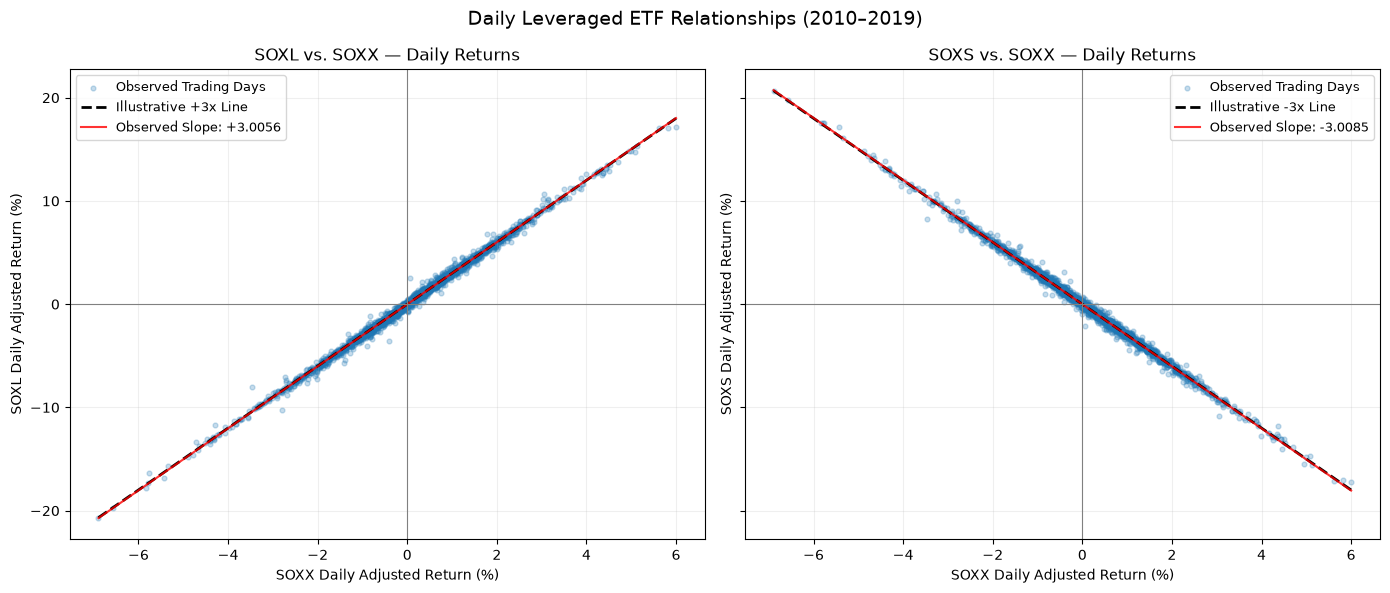

In [13]:

# ============================================================
# 2.4.5 — Daily Leverage Scatterplots
# Development period: October 18, 2010 – December 31, 2019
# ============================================================

# SOXX is the common comparison variable on the X-axis.
x_returns = leverage_comparison["SOXX Return (%)"]

# Create a range of SOXX returns for drawing reference lines.
line_x = np.linspace(
    x_returns.min(),
    x_returns.max(),
    200
)

# Create two charts side by side.
fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(14, 6),
    sharex=True,
    sharey=True
)

for ax, ticker in zip(axes, ["SOXL", "SOXS"]):

    # Retrieve the leveraged ETF's daily returns.
    y_returns = leverage_comparison[f"{ticker} Return (%)"]

    # Read the observed regression results.
    observed_slope = leverage_regression.loc[
        ticker, "Observed Slope"
    ]

    intercept = leverage_regression.loc[
        ticker, "Intercept (%)"
    ]

    illustrative_slope = leverage_regression.loc[
        ticker, "Illustrative Slope"
    ]

    # Plot each matched trading day as a dot.
    ax.scatter(
        x_returns,
        y_returns,
        s=12,
        alpha=0.25,
        label="Observed Trading Days"
    )

    # Plot the illustrative +3x or -3x reference line.
    ax.plot(
        line_x,
        illustrative_slope * line_x,
        color="black",
        linestyle="--",
        linewidth=2,
        label=f"Illustrative {illustrative_slope:+.0f}x Line"
    )

    # Plot the fitted regression relationship.
    fitted_y = intercept + observed_slope * line_x

    ax.plot(
        line_x,
        fitted_y,
        color="red",
        linewidth=1.5,
        alpha=0.8,
        label=f"Observed Slope: {observed_slope:+.4f}"
    )

    # Mark zero returns on both axes.
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.axvline(0, color="gray", linewidth=0.8)

    ax.set_title(f"{ticker} vs. SOXX — Daily Returns")
    ax.set_xlabel("SOXX Daily Adjusted Return (%)")
    ax.set_ylabel(f"{ticker} Daily Adjusted Return (%)")

    ax.legend(fontsize=9)
    ax.grid(alpha=0.2)

fig.suptitle(
    "Daily Leveraged ETF Relationships (2010–2019)",
    fontsize=14
)

plt.tight_layout()
plt.show()



### 2.4.6 — Findings from Daily Leverage Scatterplots

#### 1. SOXL Followed a Strong Positive Linear Relationship

The SOXL–SOXX scatterplot shows a narrow, upward-sloping pattern across 2,317 matched trading days.

The observed regression slope was **+3.0056**, compared with the illustrative +3x reference slope.

The fitted regression line and illustrative reference line nearly overlap.

This is consistent with SOXL having approximately three times the daily return sensitivity of SOXX during the comparison period.

#### 2. SOXS Followed a Strong Negative Linear Relationship

The SOXS–SOXX scatterplot shows a narrow, downward-sloping pattern.

The observed regression slope was **-3.0085**, compared with the illustrative -3x reference slope.

SOXS generally moved in the opposite direction to SOXX, with substantially larger daily percentage movements.

#### 3. Individual Observations Deviated from the Reference Lines

Although most observations were concentrated near the illustrative leverage lines, some dots fell above or below them.

This indicates that the simple +3x and -3x SOXX calculations did not reproduce every observed ETF return exactly.

A regression slope summarizes the average linear relationship across the sample. It does not guarantee an exact relationship on individual trading days.

#### 4. The Regression and Reference Lines Were Nearly Identical

The observed regression slopes were close to the illustrative leverage multiples:

| ETF | Observed Slope | Illustrative Slope |
|---|---:|---:|
| SOXL | +3.0056 | +3.0000 |
| SOXS | -3.0085 | -3.0000 |

The similarity explains why the fitted and illustrative lines visually overlap.

However, similarity between these slopes does not establish exact daily benchmark tracking.

#### 5. Methodological Limitations

SOXX is an unleveraged semiconductor-sector comparison ETF, not a verified exact historical benchmark for SOXL or SOXS.

Differences between observed ETF returns and the illustrative SOXX-based leverage lines cannot automatically be attributed to fees, financing costs, or tracking errors.

These scatterplots show contemporaneous relationships and do not establish forecasting ability.

#### Next Investigation

Quantify how much individual SOXL and SOXS daily returns differed from the illustrative +3x and -3x SOXX relationships.

This will help us distinguish a strong overall regression relationship from the variability of individual daily observations.



### 2.4.7 — Quantifying Daily Leverage Deviations

#### Objective

Measure how much SOXL and SOXS daily returns differed from illustrative +3x and -3x multiples of SOXX daily returns.

Our previous regression results were close to these reference relationships:

| ETF | Observed Regression Slope | Illustrative Slope |
|---|---:|---:|
| SOXL | +3.0056 | +3.0000 |
| SOXS | -3.0085 | -3.0000 |

However, a regression slope summarizes thousands of observations. It does not tell us how much individual trading days deviated from the reference.

#### What Is a Daily Leverage Deviation?

A daily leverage deviation is the difference between an ETF's observed return and its illustrative return based on SOXX.

For SOXL:

$$
D_{\mathrm{SOXL},t}
=
R_{\mathrm{SOXL},t}-3R_{\mathrm{SOXX},t}
$$

For SOXS:

$$
D_{\mathrm{SOXS},t}
=
R_{\mathrm{SOXS},t}+3R_{\mathrm{SOXX},t}
$$

The addition in the SOXS equation occurs because its illustrative leverage multiple is negative.

#### Worked Example — SOXL

Suppose SOXX gains 2% in one trading day.

The illustrative SOXL return is:

$$
3\times2\%=6\%
$$

If SOXL actually gains 5.7%, the deviation is:

$$
5.7\%-6.0\%=-0.3
\text{ percentage points}
$$

SOXL's observed return was 0.3 percentage points below the illustrative return.

#### Worked Example — SOXS

Suppose SOXX gains 2%, and SOXS loses 5.8%.

The illustrative SOXS return is:

$$
-3\times2\%=-6\%
$$

The deviation is:

$$
-5.8\%-(-6.0\%)=+0.2
\text{ percentage points}
$$

SOXS's observed return was 0.2 percentage points above its illustrative return.

#### What Is an Absolute Deviation?

An absolute deviation removes the sign:

$$
|D_t|
$$

For example:

| Signed Deviation | Absolute Deviation |
|---|---:|
| -0.3 percentage points | 0.3 percentage points |
| +0.2 percentage points | 0.2 percentage points |
| -1.5 percentage points | 1.5 percentage points |

This helps us measure the size of deviations without positive and negative differences cancelling each other out.

#### Summary Measures

We will calculate four useful statistics:

**Mean Deviation**

The average signed difference. Positive and negative deviations can cancel each other out.

**Mean Absolute Deviation**

The average size of the deviations, ignoring their direction.

This is also commonly called the mean absolute error (MAE) when evaluating differences from a reference.

**95th Percentile of Absolute Deviation**

A value at or below which approximately 95% of the observed absolute deviations fall.

It helps describe the larger deviations without relying entirely on the single most extreme observation.

**Maximum Absolute Deviation**

The largest observed deviation magnitude during the comparison period.

#### Important Methodological Distinction

These are **SOXX-relative illustrative leverage deviations**, not official ETF tracking errors.

SOXX was not necessarily the exact benchmark underlying SOXL or SOXS.

Differences may reflect benchmark composition, fund expenses, financing costs, market conditions, adjusted-price methodology, and other factors.

We cannot isolate these causes using the deviation calculation alone.

#### Research Restrictions

All calculations use the same 2,317 matched trading days from October 18, 2010 through December 31, 2019.

This is descriptive historical analysis. No forecasting model is being trained or evaluated.


In [14]:

# ============================================================
# 2.4.7 — SOXX-Relative Daily Leverage Deviations
# Development period: October 18, 2010 – December 31, 2019
# ============================================================

# Create a separate table to preserve our existing dataset.
leverage_deviations = leverage_comparison.copy()

# Reference daily returns based on illustrative leverage.
leverage_deviations["SOXL Reference (%)"] = (
    3 * leverage_deviations["SOXX Return (%)"]
)

leverage_deviations["SOXS Reference (%)"] = (
    -3 * leverage_deviations["SOXX Return (%)"]
)

# Calculate observed return minus illustrative return.
for ticker in ["SOXL", "SOXS"]:

    leverage_deviations[f"{ticker} Deviation (pp)"] = (
        leverage_deviations[f"{ticker} Return (%)"]
        - leverage_deviations[f"{ticker} Reference (%)"]
    )

    # Absolute deviation measures the size of the difference.
    leverage_deviations[f"{ticker} Absolute Deviation (pp)"] = (
        leverage_deviations[f"{ticker} Deviation (pp)"].abs()
    )

# Calculate descriptive statistics for each ETF.
deviation_rows = []

for ticker in ["SOXL", "SOXS"]:

    deviation = leverage_deviations[f"{ticker} Deviation (pp)"]
    absolute_deviation = deviation.abs()

    deviation_rows.append({
        "ETF": ticker,
        "Matched Days": deviation.count(),
        "Mean Deviation (pp)": deviation.mean(),
        "Mean Absolute Deviation (pp)": absolute_deviation.mean(),
        "95th Percentile Absolute (pp)": absolute_deviation.quantile(0.95),
        "Maximum Absolute Deviation (pp)": absolute_deviation.max()
    })

deviation_summary = pd.DataFrame(deviation_rows).set_index("ETF")

# Validate our results.
assert len(leverage_deviations) == 2317

assert np.isfinite(
    deviation_summary.select_dtypes(include="number").to_numpy()
).all()

print("SOXX-Relative Daily Leverage Deviation Summary")
print("All deviation measures are in percentage points.")
print("These are NOT official benchmark tracking errors.\n")

display(deviation_summary.round(4))

# Display a few daily examples to inspect the calculation.
print("\nFirst Five SOXL Daily Deviation Calculations")

display(
    leverage_deviations[
        [
            "Date",
            "SOXX Return (%)",
            "SOXL Return (%)",
            "SOXL Reference (%)",
            "SOXL Deviation (pp)",
            "SOXL Absolute Deviation (pp)"
        ]
    ].head(5).round(4)
)


SOXX-Relative Daily Leverage Deviation Summary
All deviation measures are in percentage points.
These are NOT official benchmark tracking errors.



,Matched Days,Mean Deviation (pp),Mean Absolute Deviation (pp),95th Percentile Absolute (pp),Maximum Absolute Deviation (pp)
ETF,,,,,
SOXL,2317,-0.0086,0.1878,0.5328,2.3481
SOXS,2317,-0.0074,0.1986,0.5760,2.0993



First Five SOXL Daily Deviation Calculations


,Date,SOXX Return (%),SOXL Return (%),SOXL Reference (%),SOXL Deviation (pp),SOXL Absolute Deviation (pp)
153,2010-10-18,-0.6818,-2.3180,-2.0454,-0.2725,0.2725
154,2010-10-19,-1.3938,-4.1909,-4.1815,-0.0095,0.0095
155,2010-10-20,0.6751,1.6724,2.0253,-0.3529,0.3529
156,2010-10-21,-0.5867,-1.4868,-1.7601,0.2733,0.2733
157,2010-10-22,1.9392,5.9408,5.8177,0.1231,0.1231



### 2.4.8 — Findings from Daily Leverage Deviations

#### 1. Average Signed Deviations Were Close to Zero

Across 2,317 matched trading days, the mean SOXX-relative deviations were:

- SOXL: **-0.0086 percentage points**
- SOXS: **-0.0074 percentage points**

These values indicate that positive and negative daily differences largely offset each other over the comparison period.

However, a mean close to zero does not mean that individual daily deviations were always small.

#### 2. Mean Absolute Deviations Were Below 0.2 Percentage Points

The mean absolute deviations were:

| ETF | Mean Absolute Deviation |
|---|---:|
| SOXL | 0.1878 percentage points |
| SOXS | 0.1986 percentage points |

Absolute deviations measure the size of the differences without allowing positive and negative values to cancel.

SOXS had a slightly larger mean absolute deviation than SOXL.

For example, SOXL's value of 0.1878 means its observed daily return differed from the illustrative +3x SOXX return by approximately 0.1878 percentage points on average.

This does not mean its return differed by 0.1878% in relative terms.

#### 3. Most Absolute Deviations Were Relatively Small

The 95th percentile absolute deviations were:

- SOXL: **0.5328 percentage points**
- SOXS: **0.5760 percentage points**

Approximately 95% of observed daily absolute deviations were at or below these respective levels.

The remaining observations had larger deviations.

These results are descriptive statistics from the development period, not future probability estimates.

#### 4. Occasional Large Deviations Still Occurred

The maximum observed absolute deviations were:

- SOXL: **2.3481 percentage points**
- SOXS: **2.0993 percentage points**

These values were substantially larger than the corresponding mean absolute deviations.

This distinction is important: a historical regression slope close to +3 or -3 does not guarantee that every trading day closely follows the illustrative leverage relationship.

#### 5. These Are Not Official Tracking Errors

The deviations were calculated relative to SOXX:

$$
D_{\mathrm{SOXL},t}
=R_{\mathrm{SOXL},t}-3R_{\mathrm{SOXX},t}
$$

$$
D_{\mathrm{SOXS},t}
=R_{\mathrm{SOXS},t}+3R_{\mathrm{SOXX},t}
$$

SOXX is a semiconductor-sector comparison ETF, not necessarily the exact benchmark underlying the leveraged funds.

The calculated differences may reflect benchmark differences, fund costs, financing, pricing methodology, and other effects.

We cannot identify the individual causes from these calculations.

Therefore, the results must be described as **SOXX-relative illustrative leverage deviations**, not official fund tracking errors.

#### Research Implication

SOXL and SOXS exhibited strong daily relationships close to illustrative +3x and -3x SOXX returns.

Their average absolute deviations were relatively small, but some individual daily deviations exceeded two percentage points.

This shows why measuring a regression slope alone is insufficient to describe the entire historical relationship.

The next step is to visualize the distribution of these deviations and investigate whether they are concentrated near zero or include notable extreme observations.



### 2.4.9 — Visualizing Daily Leverage Deviations

#### Objective

Examine the distribution of SOXL's and SOXS's daily deviations from illustrative +3x and -3x SOXX returns.

Our earlier calculations showed that the mean absolute deviations were approximately 0.19–0.20 percentage points, but the largest individual deviations exceeded two percentage points.

We now want to visualize how frequently different deviation sizes occurred.

#### Understanding Signed Deviations

A signed deviation can be positive, negative, or zero.

$$
D_t = R_{\mathrm{observed},t} - R_{\mathrm{reference},t}
$$

- **Positive deviation:** The observed ETF return was higher than the illustrative reference return.
- **Negative deviation:** The observed ETF return was lower than the illustrative reference return.
- **Zero deviation:** The observed return exactly matched the illustrative reference.

For example, suppose SOXL's illustrative return is +6%.

| Observed SOXL Return | Signed Deviation |
|---|---:|
| +6.3% | +0.3 percentage points |
| +5.7% | -0.3 percentage points |
| +6.0% | 0.0 percentage points |

The deviation measures the difference between two returns. It is not the ETF's return itself.

#### Why Use a Histogram?

A histogram shows how often different signed deviations occurred.

For our visualization:

- **X-axis:** Signed daily deviation in percentage points
- **Y-axis:** Number of matched trading days
- **Vertical dashed line:** Zero deviation
- **Bars to the left of zero:** Observed returns below the illustrative reference
- **Bars to the right of zero:** Observed returns above the illustrative reference

We will use bins that are 0.1 percentage points wide.

Both ETFs will use identical horizontal and vertical scales for comparison.

#### What Are We Looking For?

1. Are most deviations concentrated near zero?
2. Does one ETF have a visibly wider deviation distribution?
3. Are there observations far from zero?
4. Do positive and negative deviations appear on both sides?

#### Important Limitation

These are deviations from illustrative SOXX-based leverage calculations.

They are **not official tracking errors**, because SOXX is not necessarily the exact underlying benchmark of SOXL or SOXS.

The charts cannot identify the specific causes of deviations or establish future tracking performance.

Only the October 18, 2010–December 31, 2019 development-period comparison is used.


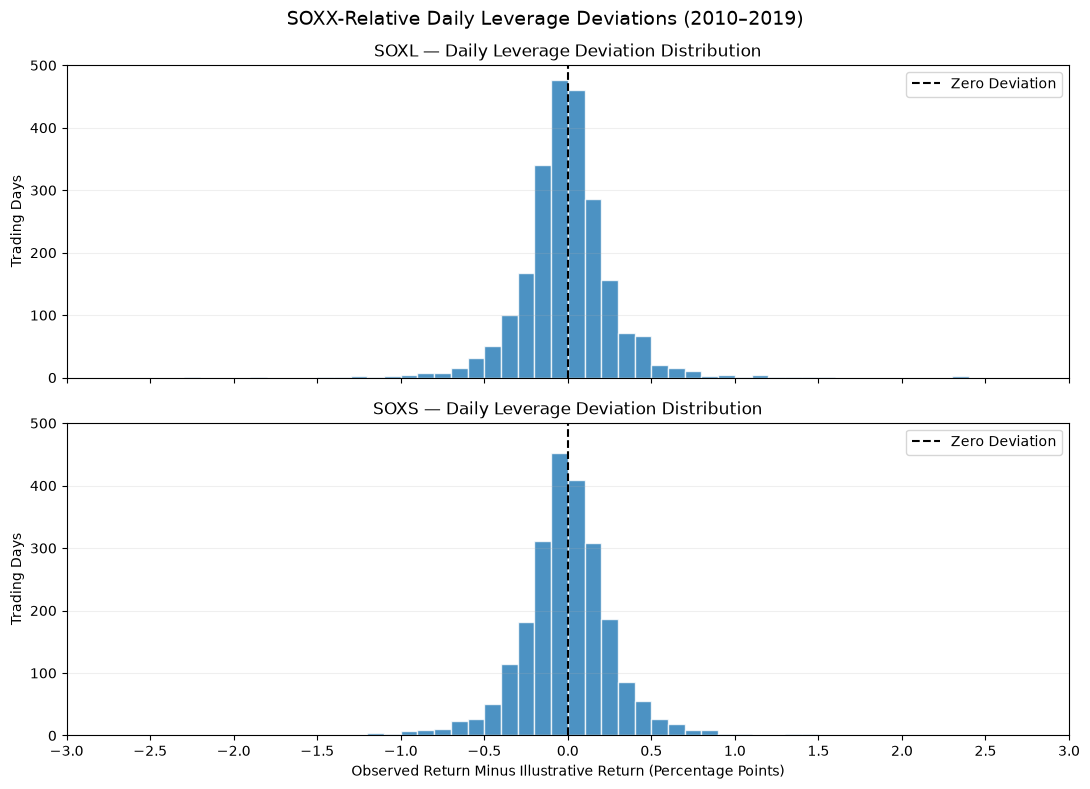

In [15]:

# ============================================================
# 2.4.9 — Daily Leverage Deviation Histograms
# Development period: October 18, 2010 – December 31, 2019
# ============================================================

# Create common bins from -3 to +3 percentage points.
# Each bin has a width of 0.1 percentage points.
bins = np.arange(-3, 3.1, 0.1)

# Create two vertically stacked histograms.
fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(11, 8),
    sharex=True,
    sharey=True
)

for ax, ticker in zip(axes, ["SOXL", "SOXS"]):

    # Retrieve the signed daily deviations.
    deviations = leverage_deviations[
        f"{ticker} Deviation (pp)"
    ]

    # Confirm that every observation fits within our bins.
    assert deviations.notna().all()
    assert deviations.between(-3, 3).all()

    # Draw the distribution.
    ax.hist(
        deviations,
        bins=bins,
        alpha=0.8,
        edgecolor="white"
    )

    # Mark zero deviation.
    ax.axvline(
        x=0,
        color="black",
        linestyle="--",
        linewidth=1.5,
        label="Zero Deviation"
    )

    ax.set_title(f"{ticker} — Daily Leverage Deviation Distribution")
    ax.set_ylabel("Trading Days")
    ax.legend()
    ax.grid(axis="y", alpha=0.2)

# Keep both histograms on identical horizontal scales.
axes[-1].set_xlim(-3, 3)
axes[-1].set_xticks(np.arange(-3, 3.5, 0.5))

axes[-1].set_xlabel(
    "Observed Return Minus Illustrative Return (Percentage Points)"
)

fig.suptitle(
    "SOXX-Relative Daily Leverage Deviations (2010–2019)",
    fontsize=14
)

plt.tight_layout()
plt.show()



### 2.4.10 — Daily Leverage Relationships: Overall Findings

#### 1. Daily Deviations Were Concentrated Near Zero

The SOXL and SOXS deviation histograms show that most observed daily returns were relatively close to their illustrative +3x and -3x SOXX-based reference returns.

Both distributions have pronounced central peaks near zero.

This is consistent with the mean absolute deviations calculated earlier:

- SOXL: 0.1878 percentage points
- SOXS: 0.1986 percentage points

The narrow central distributions indicate that relatively small deviations were common during the comparison period.

#### 2. SOXS Had a Slightly Larger Average Absolute Deviation

SOXS had a mean absolute deviation of 0.1986 percentage points, compared with 0.1878 for SOXL.

The 95th percentile absolute deviation was also slightly higher for SOXS:

| ETF | 95th Percentile Absolute Deviation |
|---|---:|
| SOXL | 0.5328 percentage points |
| SOXS | 0.5760 percentage points |

This indicates that SOXS generally had somewhat larger SOXX-relative deviations according to these measures.

The differences were modest and do not establish that one fund tracked its actual benchmark more accurately than the other.

#### 3. Large Individual Deviations Still Occurred

The histograms show relatively few observations far from zero.

However, the maximum absolute deviations were:

- SOXL: 2.3481 percentage points
- SOXS: 2.0993 percentage points

These observations show that the illustrative leverage relationships did not hold exactly on every trading day.

A regression slope close to +3 or -3 can conceal substantial differences on individual dates.

#### 4. Deviations Occurred in Both Directions

Both histograms contain positive and negative deviations.

A positive deviation means the observed ETF return exceeded its illustrative reference return.

A negative deviation means the observed ETF return fell below its illustrative reference return.

The signed means were slightly negative:

- SOXL: -0.0086 percentage points
- SOXS: -0.0074 percentage points

These small signed averages should not be confused with the typical magnitude of deviations, because positive and negative differences can cancel.

---

### Section 2.4 — Overall Conclusion

The analysis of 2,317 matched trading days from October 18, 2010 through December 31, 2019 established several descriptive relationships.

**Strong daily-return correlations**

SOXL and SOXX had a correlation of +0.9980. SOXS and SOXX had a correlation of -0.9979.

These results indicate strong contemporaneous relationships consistent with long and inverse semiconductor exposure.

**Regression slopes close to illustrative daily leverage**

The observed slopes were:

| ETF | Observed Slope | Illustrative Slope |
|---|---:|---:|
| SOXL | +3.0056 | +3.0000 |
| SOXS | -3.0085 | -3.0000 |

Both estimates were close to illustrative daily leverage multiples.

**Individual returns were not exact multiples**

Although the fitted regression lines nearly overlapped the illustrative reference lines, daily deviations occurred.

The mean absolute deviations were approximately 0.19–0.20 percentage points, and the largest observed deviations exceeded two percentage points.

#### Methodological Limitations

SOXX is an unleveraged semiconductor-sector comparison ETF, not necessarily the exact underlying benchmark for SOXL or SOXS.

The regression slopes and deviation statistics therefore cannot be interpreted as official fund tracking-accuracy measurements.

Historical benchmark differences, expenses, financing costs, derivatives, and adjusted-price methodology may affect the observed relationships.

The analysis does not isolate these effects or establish causation.

All relationships are contemporaneous and restricted to development-period observations.

#### Research Implication

SOXL and SOXS showed daily-return behaviour consistent with approximately +3x and -3x semiconductor-sector exposure.

However, a strong daily leverage relationship does not guarantee that the leveraged ETFs will deliver exactly three times the sector's cumulative return over multiple days.

Daily returns compound, and the sequence of positive and negative movements matters.

**Next: Section 2.5 — Compounding and Path Dependence**

We will investigate how daily leveraged returns accumulate over time and why multi-day performance can differ substantially from simply multiplying the sector's cumulative return by three.
